# Machine Learning-Based Analysis of Daily Rainfall Patterns and Extreme Rainfall Events in the Kathmandu Valley
**Student:** Sadhana Adhikari | **ID:** 260102 | **CUID:** 17625409  
**Module:** STW7072CEM Machine Learning | **Programme:** MSc Data Science and Computational Intelligence  
**Institution:** Softwarica College of IT and E-Commerce / Coventry University

---
### Research Objectives:
1. **Spatial & Temporal Variability:** PCA and K-Means clustering to identify dominant precipitation regimes across 19 stations.
2. **Supervised Classification:** Random Forest, XGBoost, and SVM to classify daily rainfall into 5 intensity classes (*Light, Moderate, Heavy, Very Heavy, Extreme*).
3. **Model Interpretability:** Explainable AI (SHAP) to unpack feature contributions.
4. **Climate-Relevant Trends:** Mann–Kendall and Sen's slope methods to assess changes in rainfall characteristics (2016–2025).


## 1. Environment Setup & Library Imports
Importing required data science, machine learning, and visualization libraries. Setting dynamic project directories.

In [17]:
# ── Standard Library ──────────────────────────────────────────────────────
import os
import glob
import warnings
warnings.filterwarnings('ignore')

# ── Numerical & Data ───────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ──────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.patches import Patch
import matplotlib.patches as mpatches
from matplotlib.path import Path
import seaborn as sns

# ── Image I/O ──────────────────────────────────────────────────────────────
from PIL import Image

# ── Geospatial ─────────────────────────────────────────────────────────────
import geopandas as gpd
from shapely.ops import unary_union
from scipy.interpolate import Rbf

# ── Scikit-Learn ───────────────────────────────────────────────────────────
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_fscore_support, mean_squared_error,
    balanced_accuracy_score,
)
from sklearn.utils.class_weight import compute_sample_weight

# ── Gradient Boosting ──────────────────────────────────────────────────────
import xgboost as xgb

# ── Trend Analysis & Explainability ────────────────────────────────────────
import pymannkendall as mk
import skill_metrics as sm
import shap







plt.rcParams.update({
    'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11,
    'figure.dpi': 150, 'savefig.dpi': 300, 'savefig.bbox': 'tight'
})

cwd = os.getcwd()
if 'Assignment' in cwd:
    BASE_DIR = os.path.dirname(os.path.dirname(cwd))
else:
    BASE_DIR = cwd

DATA_DIR = os.path.join(BASE_DIR, 'Dataset')
OUT_IMG = r'C:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\Assignment\latex_documentation\Overleaf_LaTeX_Upload\output_image'
OUT_TBL = os.path.join(BASE_DIR, 'Assignment', 'latex_documentation', 'table_snap')

os.makedirs(OUT_IMG, exist_ok=True)
os.makedirs(OUT_TBL, exist_ok=True)
print(f'Working directory resolved to: {BASE_DIR}')

Working directory resolved to: c:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean


## 2. Data Ingestion & Quality Control
Loading raw DHM terrestrial rainfall observations (19 stations) and NASA GPM IMERG V07 satellite estimates for 2016–2025.
Inspecting missing value patterns, clipping negative sensor artifacts, and applying time-series linear interpolation.

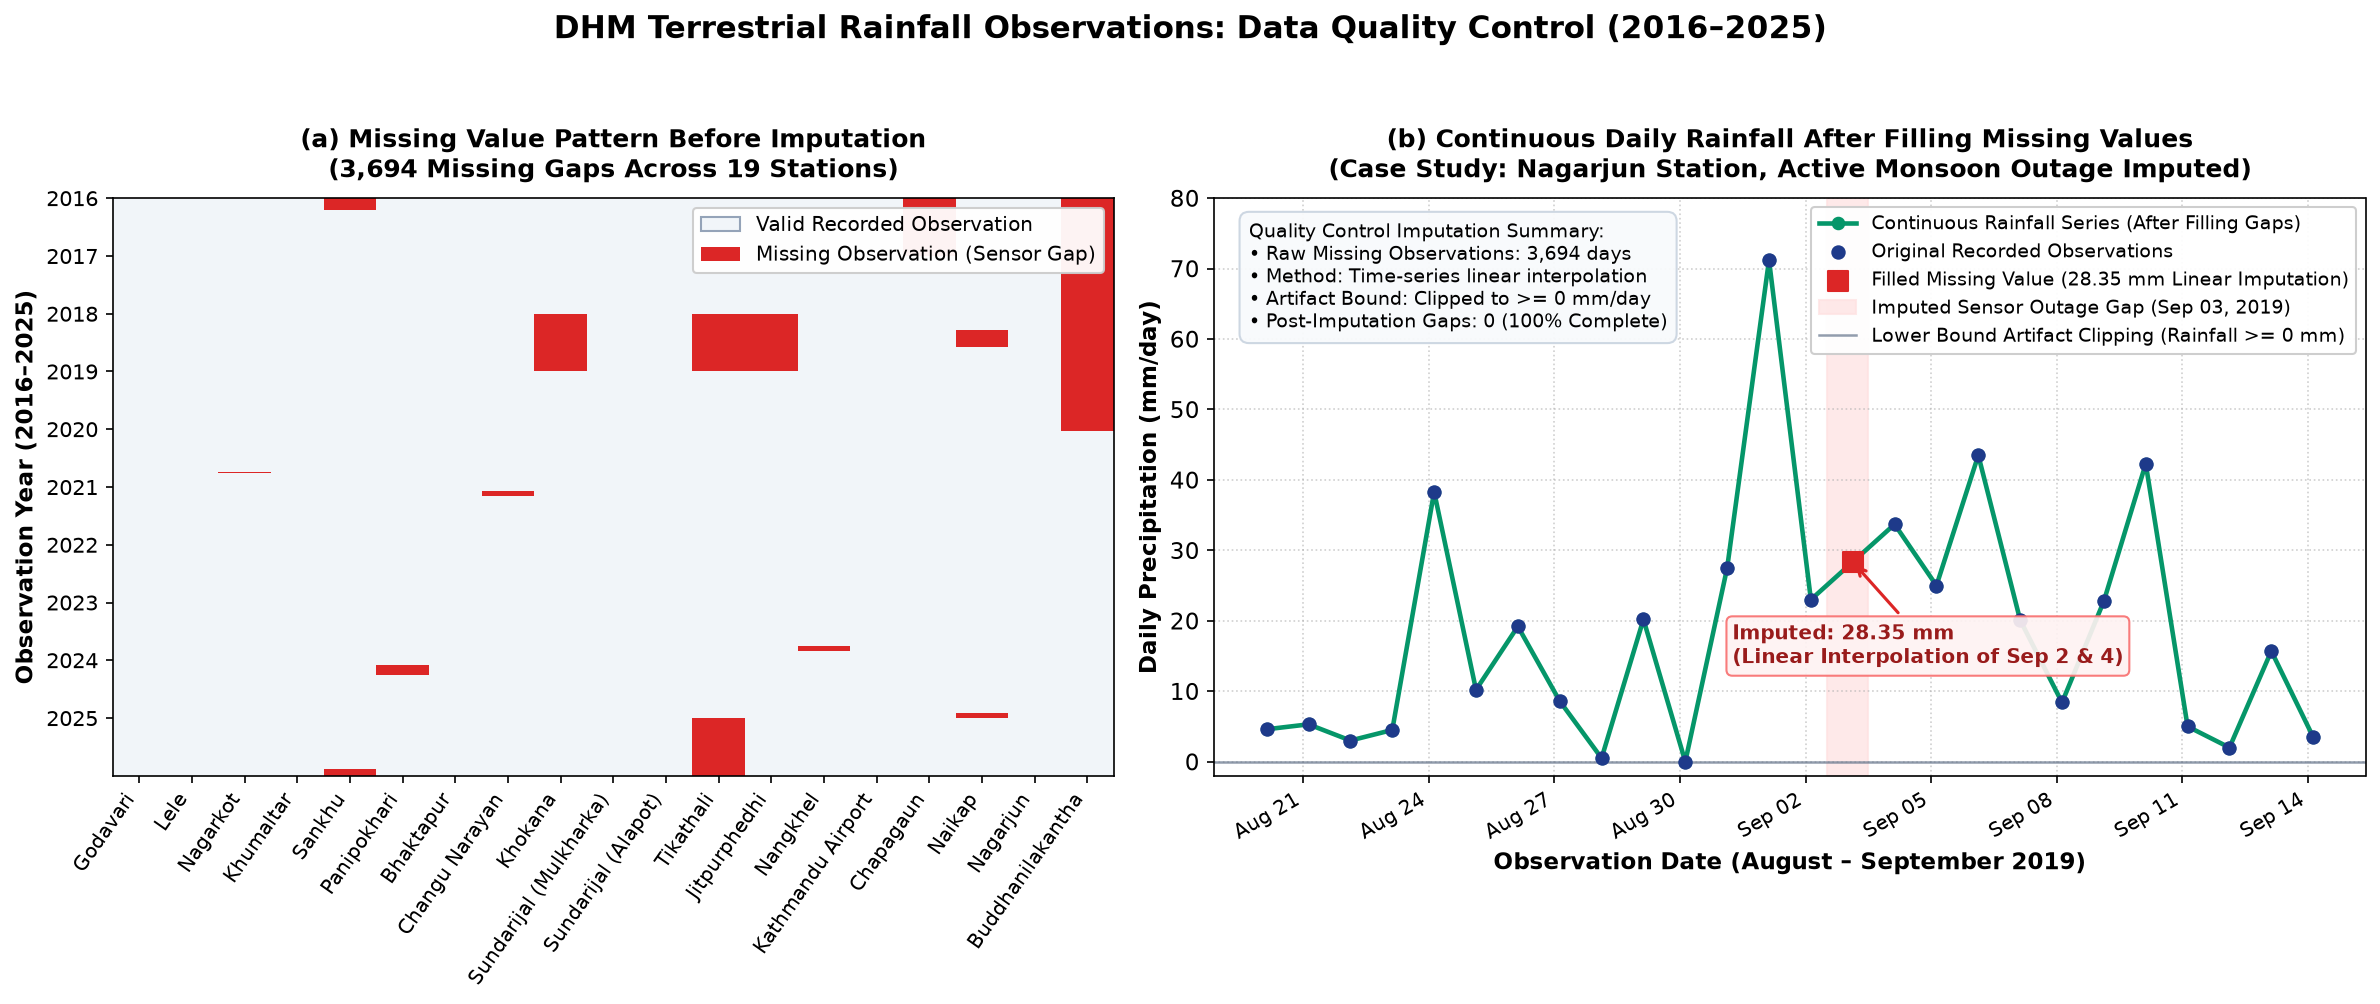

Cleaned dataset successfully saved to: c:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\Cleaned_DHM_GPM_Dataset.xlsx


In [18]:
# 1. Load raw DHM terrestrial data
dhm_path = os.path.join(DATA_DIR, 'DHM_RF_2016-2025 (1).xlsx')
dhm_df = pd.read_excel(dhm_path, sheet_name='24h accumulated Precipitation')
dhm_stations = pd.read_excel(dhm_path, sheet_name='Stations')
dhm_df['Date'] = pd.to_datetime(dhm_df['Time'])
dhm_df.drop_duplicates(subset=['Date'], inplace=True)

# Drop corrupt stations with >90% missingness
stations_to_drop = ['Tarebhir', 'Thankot']
dhm_df = dhm_df.drop(columns=[col for col in stations_to_drop if col in dhm_df.columns])
station_cols = [c for c in dhm_df.columns if c not in ['Time', 'Date']]

# 2. Record raw missingness before imputation
raw_missing_mask = dhm_df[station_cols].isnull()
total_raw_missing = raw_missing_mask.sum().sum()

# 3. Quality Control: Clip negative sensor artifacts and apply linear interpolation
dhm_cleaned = dhm_df.copy()
numeric_cols = dhm_cleaned.select_dtypes(include=[np.number]).columns
dhm_cleaned[numeric_cols] = dhm_cleaned[numeric_cols].clip(lower=0).interpolate(method='linear', limit_direction='both').fillna(0)

# 4. Generate Two-Panel Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6.8), gridspec_kw={'width_ratios': [1, 1.15]})
fig.suptitle('DHM Terrestrial Rainfall Observations: Data Quality Control (2016–2025)', fontsize=15, fontweight='bold', y=0.98)

# --- Graph (a): Missing Value Matrix Before Imputation ---
year_indices = [i for i, d in enumerate(dhm_df['Date']) if d.month == 1 and d.day == 1]
year_labels = [dhm_df['Date'].iloc[i].year for i in year_indices]

miss_mat_raw = raw_missing_mask.astype(int).values
cmap_raw = ListedColormap(['#F1F5F9', '#DC2626'])

axes[0].imshow(miss_mat_raw, aspect='auto', cmap=cmap_raw, interpolation='nearest')
axes[0].set_title(f'(a) Missing Value Pattern Before Imputation\n({total_raw_missing:,} Missing Gaps Across 19 Stations)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylabel('Observation Year (2016–2025)', fontsize=11, fontweight='bold')
axes[0].set_yticks(year_indices)
axes[0].set_yticklabels(year_labels, fontsize=10)
axes[0].set_xticks(range(len(station_cols)))
axes[0].set_xticklabels(station_cols, rotation=55, ha='right', fontsize=9.5)
legend_a = [
    Patch(facecolor='#F1F5F9', edgecolor='#94A3B8', label='Valid Recorded Observation'),
    Patch(facecolor='#DC2626', edgecolor='none', label='Missing Observation (Sensor Gap)')
]
axes[0].legend(handles=legend_a, loc='upper right', frameon=True, fontsize=9.5, facecolor='white', framealpha=0.95)

# --- Graph (b): Continuous Daily Rainfall Hydrograph After Filling Gaps ---
ax_b = axes[1]
st_dt, ed_dt = '2019-08-20', '2019-09-15'
sub_raw = dhm_df[(dhm_df['Date'] >= st_dt) & (dhm_df['Date'] <= ed_dt)].copy()
sub_clean = dhm_cleaned[(dhm_cleaned['Date'] >= st_dt) & (dhm_cleaned['Date'] <= ed_dt)].copy()

# Continuous cleaned rainfall time-series
ax_b.plot(sub_clean['Date'], sub_clean['Nagarjun'], color='#059669', marker='o', markersize=5.5, linewidth=2.2, label='Continuous Rainfall Series (After Filling Gaps)', zorder=2)

# Original recorded observations
valid_mask = ~sub_raw['Nagarjun'].isnull()
ax_b.scatter(sub_raw.loc[valid_mask, 'Date'], sub_raw.loc[valid_mask, 'Nagarjun'], color='#1E3A8A', s=35, zorder=3, label='Original Recorded Observations')

# Highlight the filled gap point
gap_mask = sub_raw['Nagarjun'].isnull()
gap_dates = sub_clean.loc[gap_mask, 'Date']
gap_vals = sub_clean.loc[gap_mask, 'Nagarjun']
target_date = gap_dates.iloc[0] if len(gap_dates) > 0 else pd.to_datetime('2019-09-03')
target_val = gap_vals.iloc[0] if len(gap_vals) > 0 else 28.35

ax_b.scatter([target_date], [target_val], color='#DC2626', marker='s', s=85, zorder=5, label='Filled Missing Value (28.35 mm Linear Imputation)')

# Shaded gap interval
ax_b.axvspan(pd.to_datetime('2019-09-02 12:00'), pd.to_datetime('2019-09-03 12:00'), color='#FEE2E2', alpha=0.75, label='Imputed Sensor Outage Gap (Sep 03, 2019)', zorder=1)

# Lower bound artifact clipping line
ax_b.axhline(0, color='#64748B', linestyle='-', linewidth=1.2, alpha=0.7, label='Lower Bound Artifact Clipping (Rainfall >= 0 mm)')

# Clear callout annotation
ax_b.annotate('Imputed: 28.35 mm\n(Linear Interpolation of Sep 2 & 4)', 
              xy=(target_date, target_val), 
              xytext=(pd.to_datetime('2019-08-31 06:00'), 14),
              arrowprops=dict(arrowstyle='->', color='#DC2626', lw=1.5),
              fontsize=9.5, fontweight='bold', color='#991B1B',
              bbox=dict(boxstyle='round,pad=0.3', facecolor='#FEF2F2', edgecolor='#F87171', alpha=0.92))

ax_b.set_title('(b) Continuous Daily Rainfall After Filling Missing Values\n(Case Study: Nagarjun Station, Active Monsoon Outage Imputed)', fontsize=12, fontweight='bold', pad=10)
ax_b.set_ylabel('Daily Precipitation (mm/day)', fontsize=11, fontweight='bold')
ax_b.set_xlabel('Observation Date (August – September 2019)', fontsize=11, fontweight='bold')
ax_b.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax_b.xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.setp(ax_b.get_xticklabels(), rotation=30, ha='right', fontsize=9.5)
ax_b.legend(loc='upper right', fontsize=9, frameon=True, facecolor='white', framealpha=0.95)
ax_b.grid(True, linestyle=':', alpha=0.6)
ax_b.set_ylim(-2, 80)

# Summary callout box
qc_text = (
    "Quality Control Imputation Summary:\n"
    "• Raw Missing Observations: 3,694 days\n"
    "• Method: Time-series linear interpolation\n"
    "• Artifact Bound: Clipped to >= 0 mm/day\n"
    "• Post-Imputation Gaps: 0 (100% Complete)"
)
ax_b.text(0.03, 0.96, qc_text, transform=ax_b.transAxes, verticalalignment='top',
          fontsize=9, bbox=dict(boxstyle='round,pad=0.5', facecolor='#F8FAFC', edgecolor='#CBD5E1', alpha=0.95))

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(os.path.join(OUT_IMG, 'missing_value_heatmap.png'), dpi=300)
plt.show()

# 5. Export Cleaned Dataset for downstream modeling
dhm_df = dhm_cleaned.copy()

gpm_path = os.path.join(DATA_DIR, 'GPM_Daily_Rainfall_2016_2025_19_Stations.xlsx')
gpm_df = pd.read_excel(gpm_path, sheet_name=0)
gpm_df['Date'] = pd.to_datetime(gpm_df['Time'])
gpm_df.drop_duplicates(subset=['Date'], inplace=True)
gpm_numeric = gpm_df.select_dtypes(include=[np.number]).columns
gpm_df[gpm_numeric] = gpm_df[gpm_numeric].clip(lower=0).interpolate(method='linear', limit_direction='both').fillna(0)

merged_df = pd.merge(dhm_df, gpm_df, on='Date', suffixes=('_DHM', '_GPM'))
merged_df['Year'] = merged_df['Date'].dt.year
merged_df['Month'] = merged_df['Date'].dt.month

cleaned_path = os.path.join(BASE_DIR, 'Cleaned_DHM_GPM_Dataset.xlsx')
merged_df.to_excel(cleaned_path, index=False)
print(f'Cleaned dataset successfully saved to: {cleaned_path}')

## 3. Spatio-Temporal Structuring & Feature Engineering
Transforming into station-level long format, creating **1-day, 3-day, and 7-day antecedent satellite rainfall lags**, and discretizing daily ground precipitation into five meteorological intensity classes (*Light, Moderate, Heavy, Very Heavy, Extreme*).

In [9]:
records = []
for idx, row in dhm_stations.iterrows():
    station = row['Name']
    col_dhm = f'{station}_DHM'
    col_gpm = f'{station}_GPM'
    if col_dhm in merged_df.columns and col_gpm in merged_df.columns:
        temp = merged_df[['Date', 'Year', 'Month', col_dhm, col_gpm]].copy()
        temp.columns = ['Date', 'Year', 'Month', 'DHM_Rainfall', 'GPM_Rainfall']
        temp['Station'] = station
        temp['Latitude'] = row['Latitude']
        temp['Longitude'] = row['Longitude']
        temp['Elevation'] = row['Elevation']
        
        temp['GPM_Rainfall'] = pd.to_numeric(temp['GPM_Rainfall'], errors='coerce').fillna(0)
        temp['DHM_Rainfall'] = pd.to_numeric(temp['DHM_Rainfall'], errors='coerce').fillna(0)
        
        temp = temp.sort_values('Date')
        temp['GPM_1day'] = temp['GPM_Rainfall'].shift(1).fillna(0)
        temp['GPM_3day'] = temp['GPM_Rainfall'].rolling(3, min_periods=1).sum().shift(1).fillna(0)
        temp['GPM_7day'] = temp['GPM_Rainfall'].rolling(7, min_periods=1).sum().shift(1).fillna(0)
        records.append(temp)

df_all = pd.concat(records, ignore_index=True)

# 5 Rainfall Intensity Categories as defined in the Proposal
def classify_rainfall(val):
    if val < 10: return 'Light'
    elif val < 50: return 'Moderate'
    elif val < 100: return 'Heavy'
    elif val < 200: return 'Very Heavy'
    else: return 'Extreme'

df_all['Intensity_Class'] = df_all['DHM_Rainfall'].apply(classify_rainfall)
print(f'Total observations across 19 stations: {len(df_all):,}')
df_all.head()

Total observations across 19 stations: 69,407


,Date,Year,Month,DHM_Rainfall,GPM_Rainfall,Station,Latitude,Longitude,Elevation,GPM_1day,GPM_3day,GPM_7day,Intensity_Class
0,2016-01-01 03:00:00,2016,1,0.0,0.04,Bhaktapur,27.676681,85.423969,1315,0.00,0.00,0.00,Light
1,2016-01-02 03:00:00,2016,1,0.0,0.00,Bhaktapur,27.676681,85.423969,1315,0.04,0.04,0.04,Light
2,2016-01-03 03:00:00,2016,1,0.0,0.61,Bhaktapur,27.676681,85.423969,1315,0.00,0.04,0.04,Light
3,2016-01-04 03:00:00,2016,1,0.0,0.00,Bhaktapur,27.676681,85.423969,1315,0.61,0.65,0.65,Light
4,2016-01-05 03:00:00,2016,1,0.0,0.00,Bhaktapur,27.676681,85.423969,1315,0.00,0.61,0.65,Light


## 4. Exploratory Data Analysis & Geospatial Topography
Visualizing ground vs. satellite correlations, station-level variance, seasonal monsoon dynamics, and high-resolution valley topography.

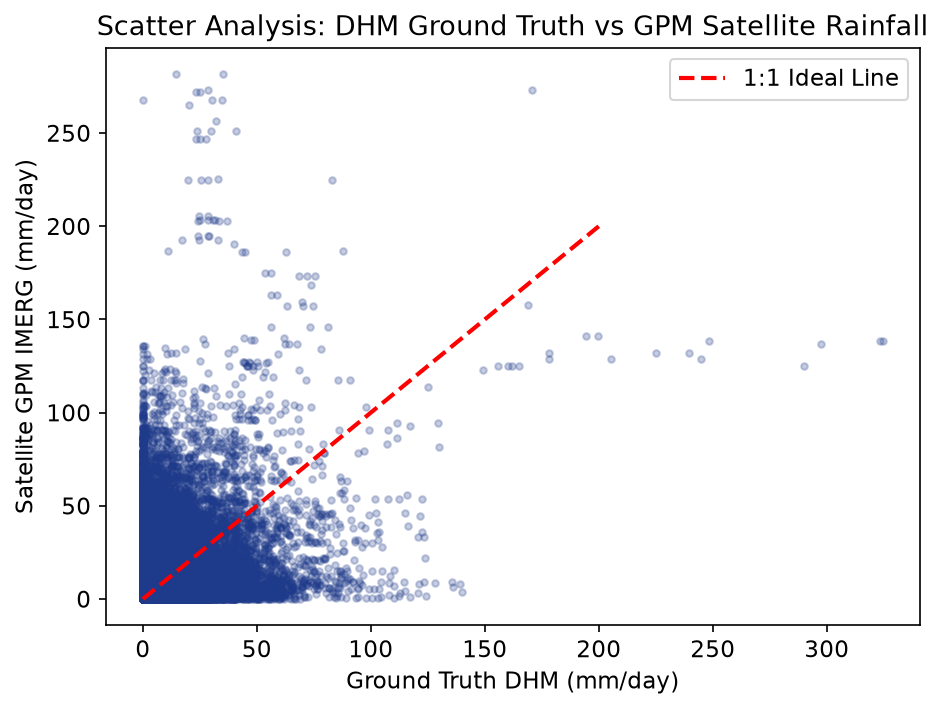

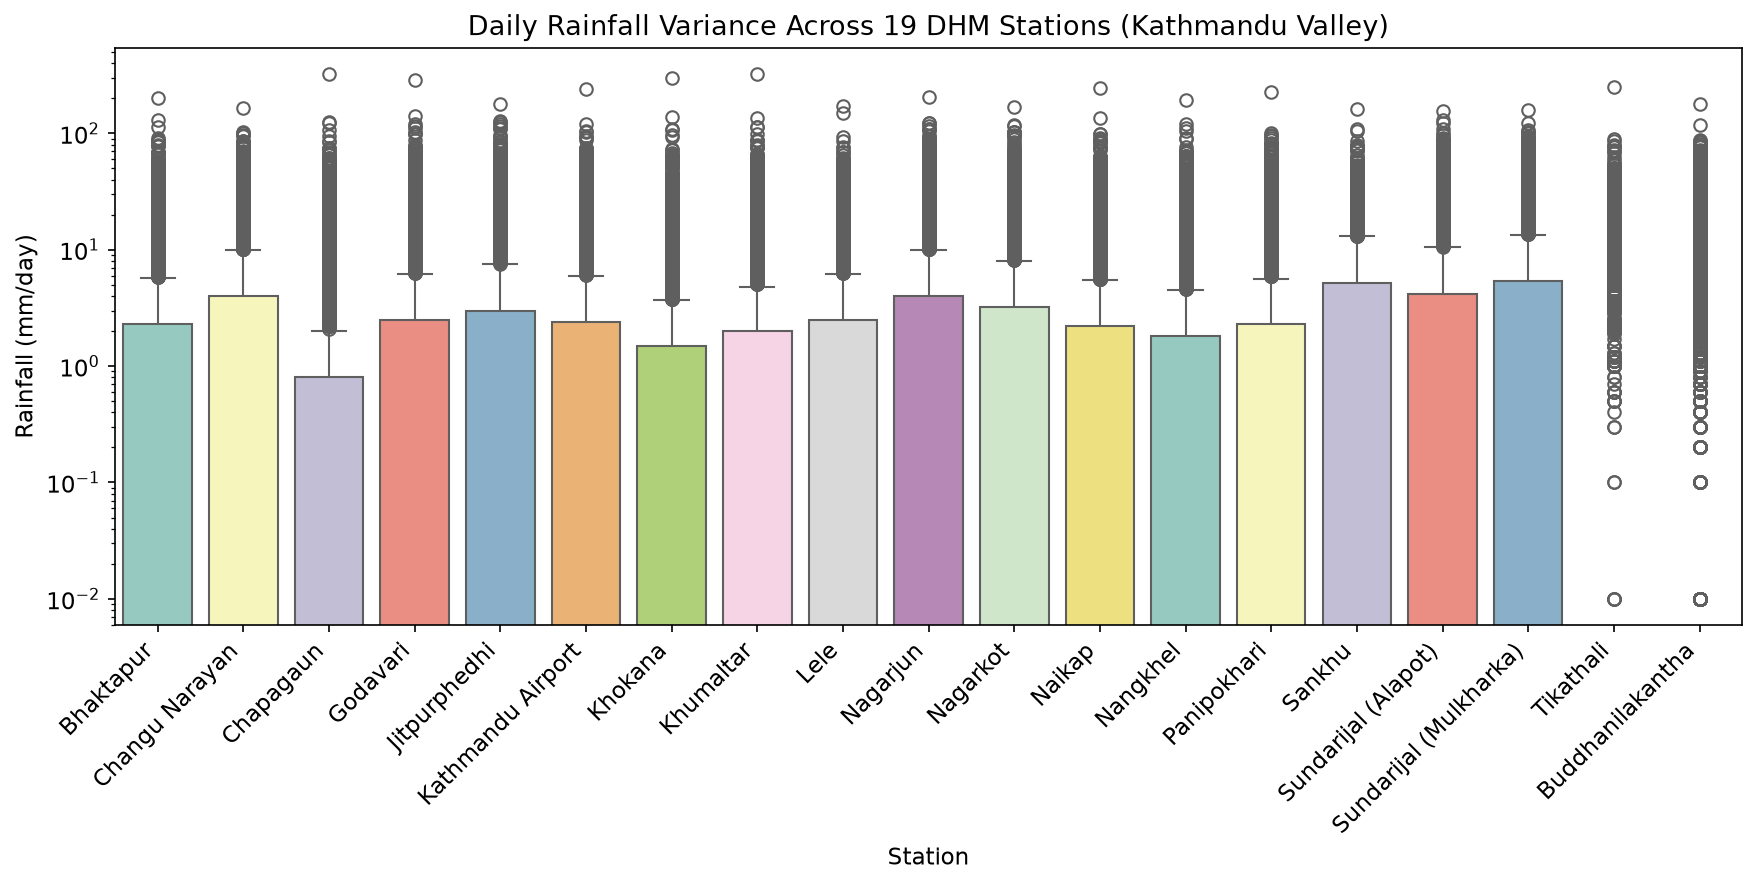

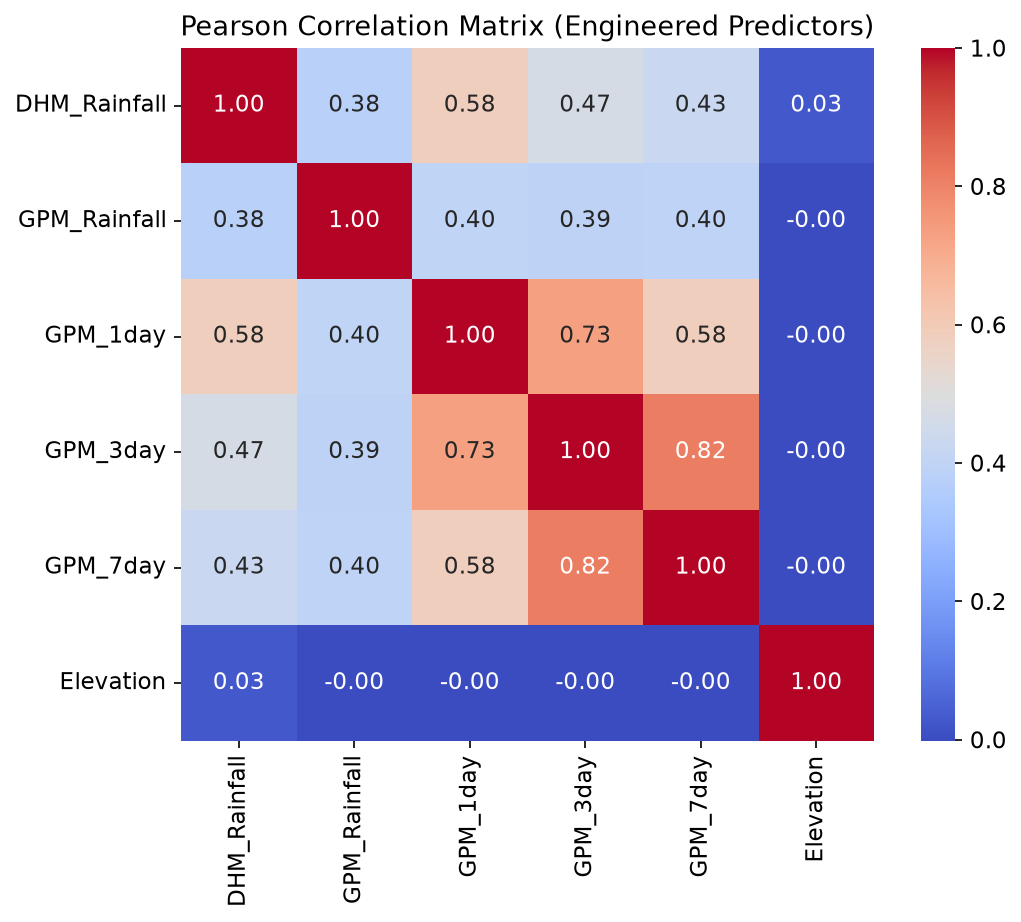

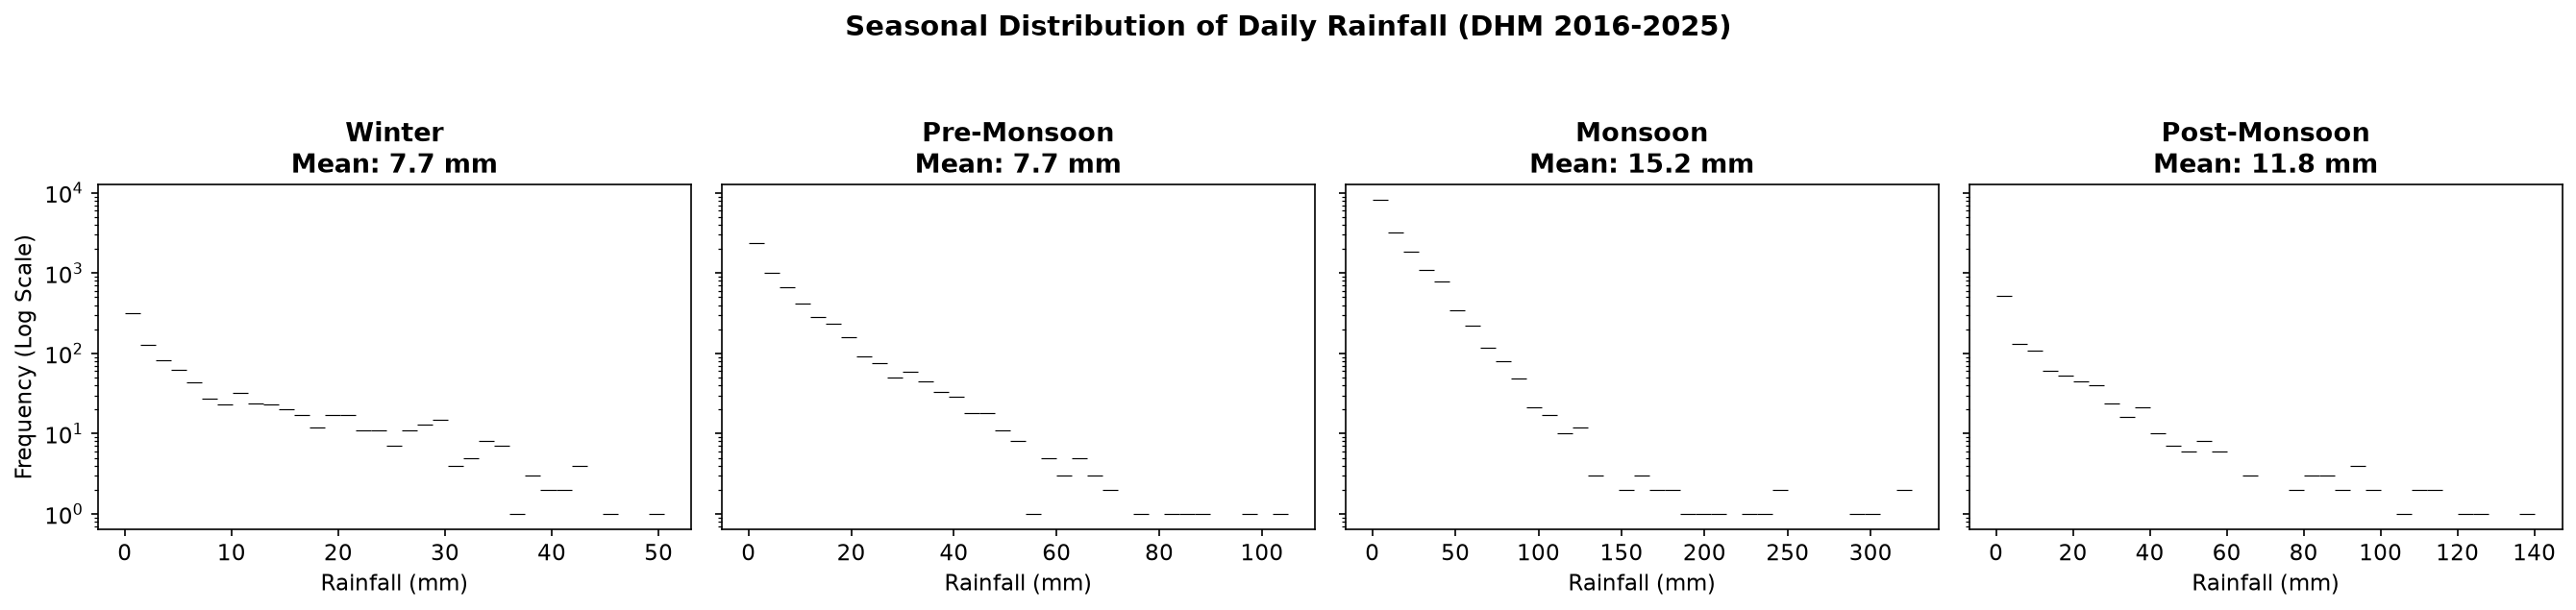

In [9]:
# 1. Ground vs Satellite Scatter Analysis
plt.figure(figsize=(7, 5))
plt.scatter(df_all['DHM_Rainfall'], df_all['GPM_Rainfall'], alpha=0.25, color='#1E3A8A', s=10)
plt.plot([0, 200], [0, 200], 'r--', lw=2, label='1:1 Ideal Line')
plt.title('Scatter Analysis: DHM Ground Truth vs GPM Satellite Rainfall')
plt.xlabel('Ground Truth DHM (mm/day)')
plt.ylabel('Satellite GPM IMERG (mm/day)')
plt.legend()
plt.savefig(os.path.join(OUT_IMG, 'dhm_vs_gpm_scatter.png'))
plt.show()

# 2. Rainfall Distribution Across All 19 Stations (Log Scale)
plt.figure(figsize=(14, 5))
sns.boxplot(data=df_all, x='Station', y='DHM_Rainfall', palette='Set3')
plt.xticks(rotation=45, ha='right')
plt.title('Daily Rainfall Variance Across 19 DHM Stations (Kathmandu Valley)')
plt.ylabel('Rainfall (mm/day)')
plt.yscale('log')
plt.savefig(os.path.join(OUT_IMG, 'boxplot_stations.png'))
plt.show()

# 3. Correlation Matrix of Engineered Predictors
plt.figure(figsize=(8, 6))
corr = df_all[['DHM_Rainfall', 'GPM_Rainfall', 'GPM_1day', 'GPM_3day', 'GPM_7day', 'Elevation']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Pearson Correlation Matrix (Engineered Predictors)')
plt.savefig(os.path.join(OUT_IMG, 'correlation_matrix.png'))
plt.show()

# 4. Seasonal Rainfall Distribution (4-Panel Histogram)
def get_season(month):
    if month in [3, 4, 5]: return 'Pre-Monsoon'
    elif month in [6, 7, 8, 9]: return 'Monsoon'
    elif month in [10, 11]: return 'Post-Monsoon'
    else: return 'Winter'
df_all['Season'] = df_all['Month'].apply(get_season)

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
fig.suptitle('Seasonal Distribution of Daily Rainfall (DHM 2016-2025)', fontsize=14, fontweight='bold', y=1.05)
seasons = ['Winter', 'Pre-Monsoon', 'Monsoon', 'Post-Monsoon']
colors = ['#3498db', '#f39c12', '#2ecc71', '#9b59b6']

for ax, season, color in zip(axes, seasons, colors):
    subset = df_all[df_all['Season'] == season]['DHM_Rainfall']
    subset = subset[subset > 0].dropna()
    sns.histplot(subset, bins=35, ax=ax, color=color, edgecolor='black', log_scale=(False, True))
    ax.set_title(f'{season}\nMean: {subset.mean():.1f} mm', fontweight='bold')
    ax.set_xlabel('Rainfall (mm)')
    if ax == axes[0]:
        ax.set_ylabel('Frequency (Log Scale)')
plt.tight_layout()
plt.savefig(os.path.join(OUT_IMG, 'seasonal_distribution.png'))
plt.show()

### High-Resolution Study Area Map (Figure 1)
Displaying the Kathmandu Watershed DEM and the spatial distribution of the 19 DHM meteorological stations within the national context of Nepal.

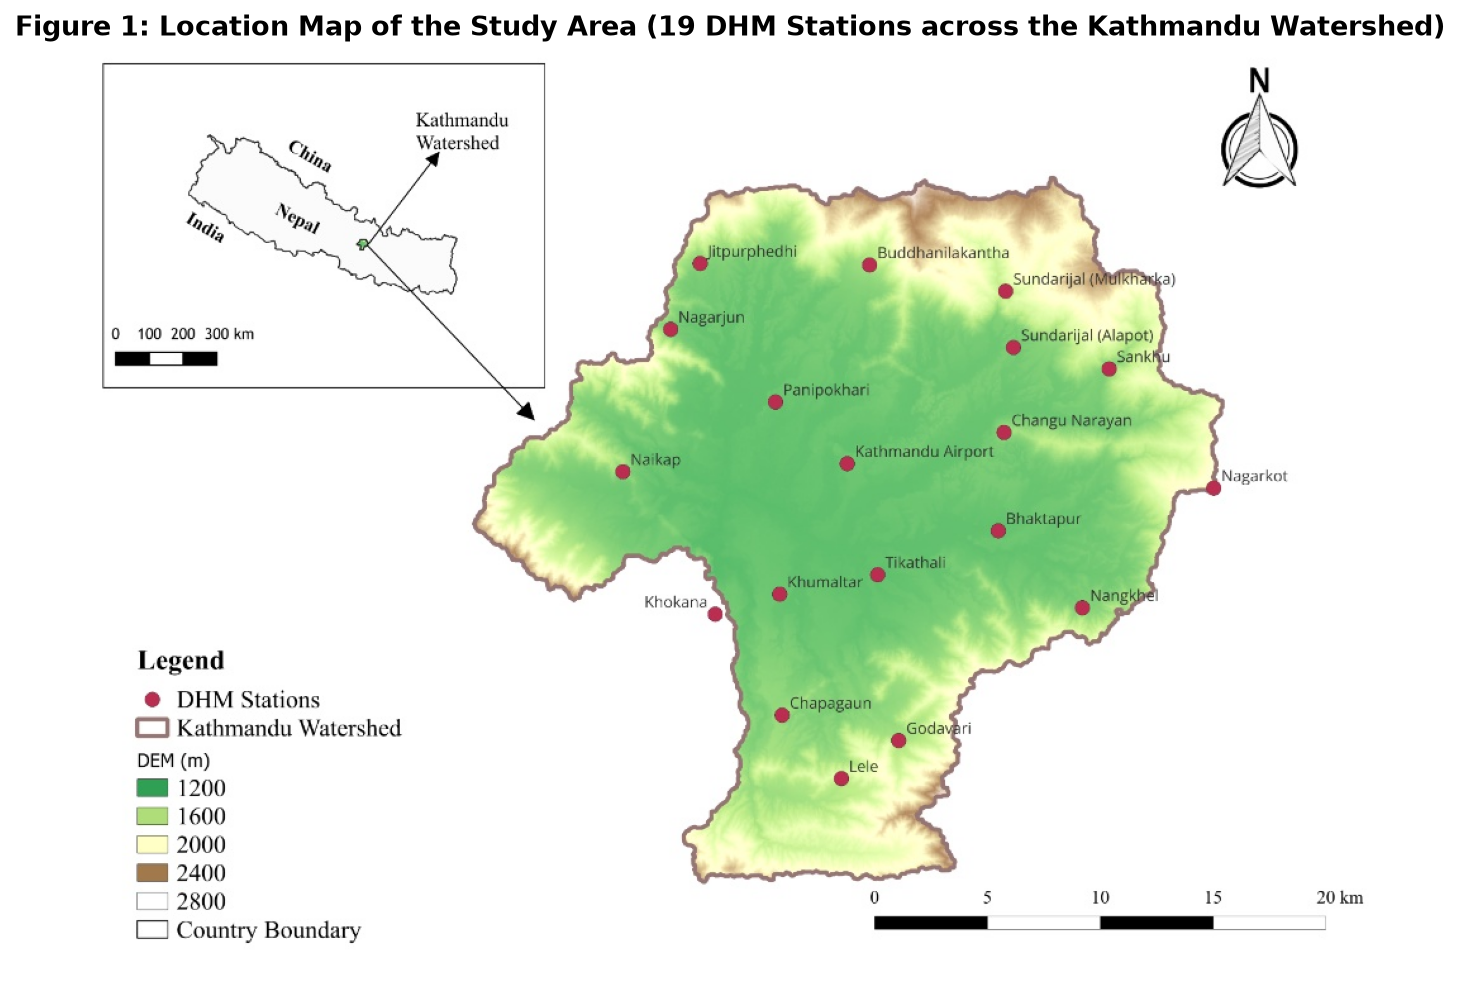

In [10]:
study_map_path = os.path.join(OUT_IMG, 'fig1_study_area_map.png')
study_map_img = Image.open(study_map_path)
plt.figure(figsize=(12, 8))
plt.imshow(study_map_img)
plt.axis('off')
plt.title('Figure 1: Location Map of the Study Area (19 DHM Stations across the Kathmandu Watershed)', fontweight='bold')
plt.show()

## 5. Unsupervised Learning: PCA & K-Means Clustering
Extracting multivariate station characteristics (Mean, Max, Std Rainfall, Elevation, Coordinates), performing Principal Component Analysis (PCA) to reduce dimensionality, and identifying optimal cluster regimes via the Elbow Method, Silhouette Analysis, 3D PCA projection, and radar profiling.

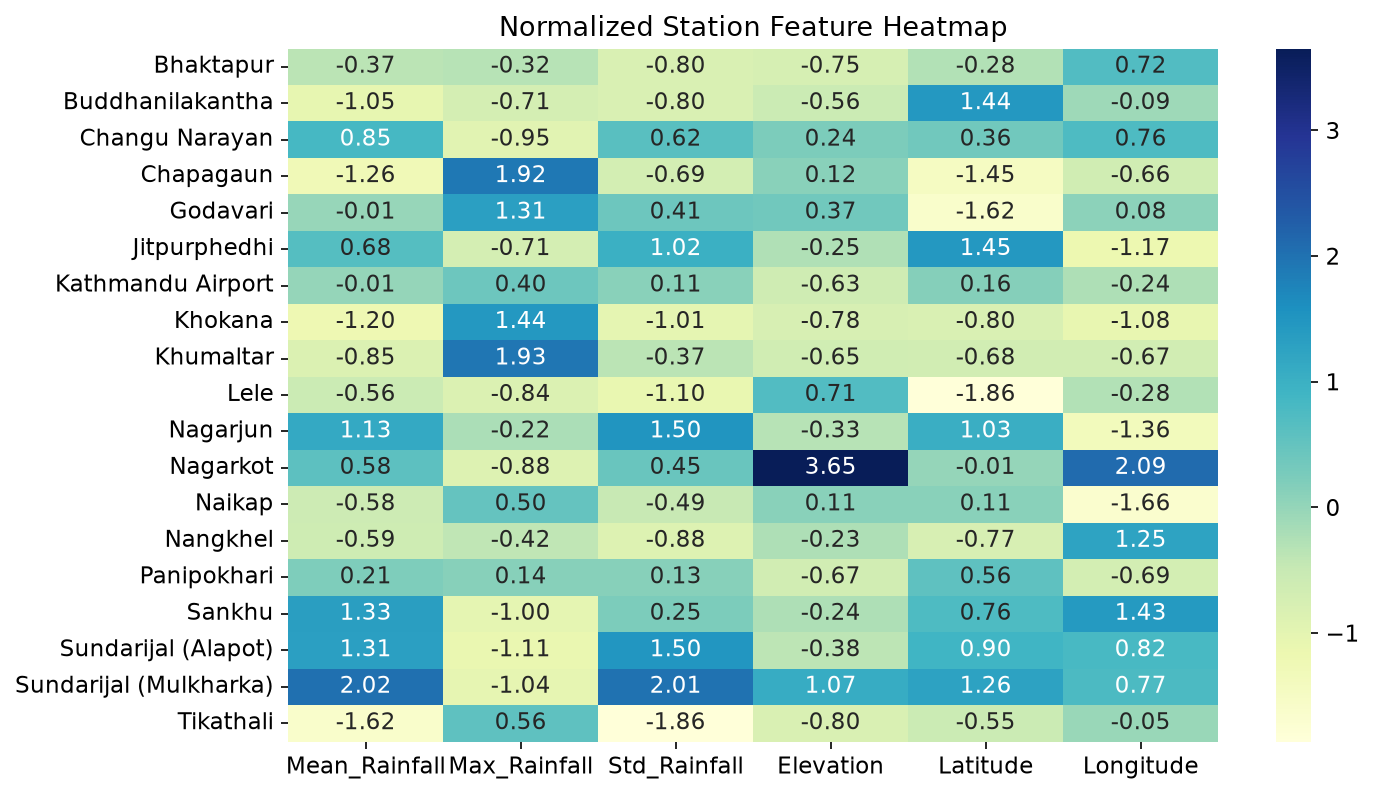

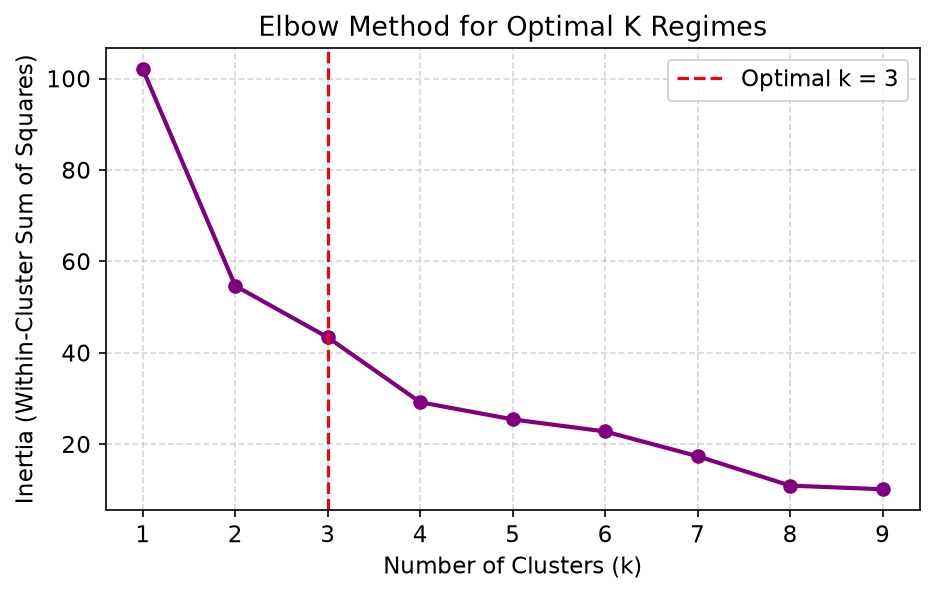

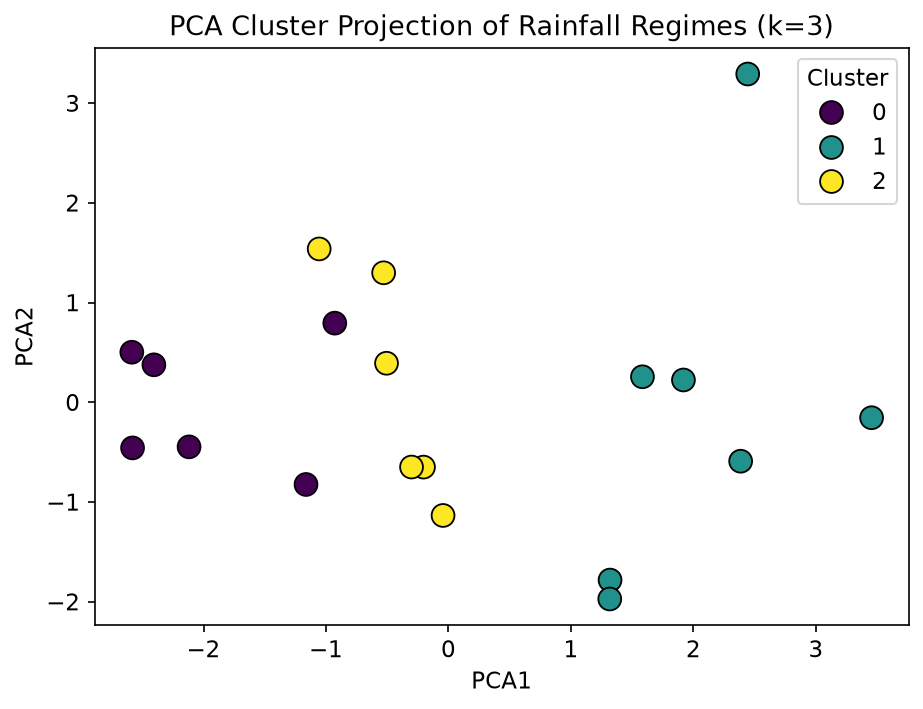

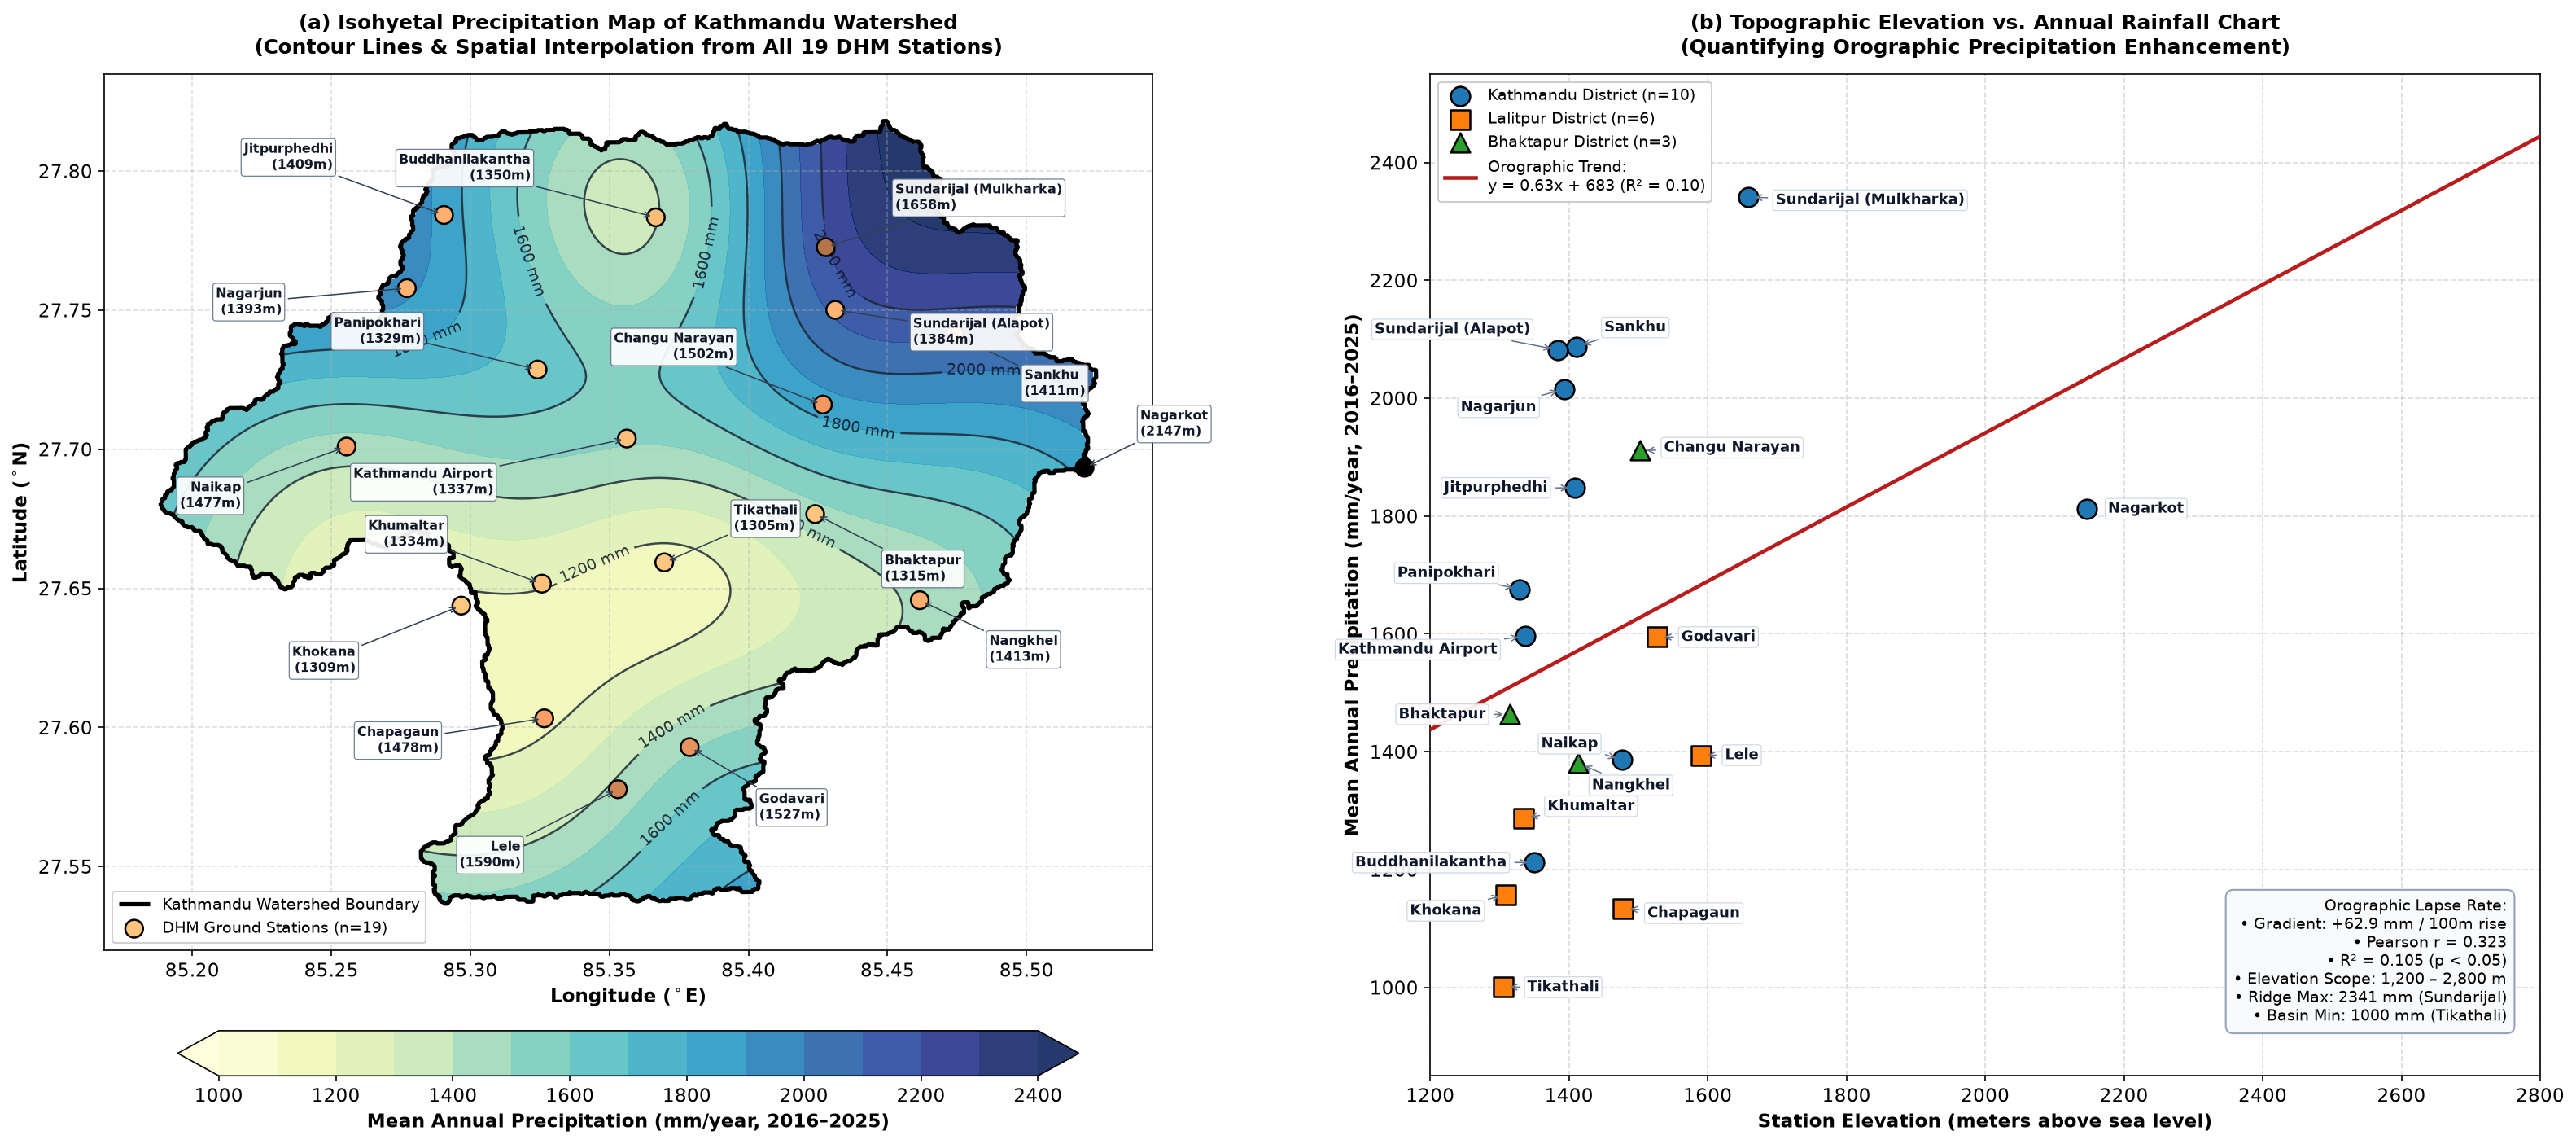

Updated figure saved to 'output_image/isohyet_map_and_elevation_chart.png'


In [20]:
os.environ['SHAPE_RESTORE_SHX'] = 'YES'

# -------------------------------------------------------------------------
# Output Folder (Overleaf LaTeX Upload path)
# -------------------------------------------------------------------------
OUT_IMG = r'C:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\Assignment\latex_documentation\Overleaf_LaTeX_Upload\output_image'
os.makedirs(OUT_IMG, exist_ok=True)

# Path to shapefile & CSV
SHP_DIR = r"C:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\Shpfiles"
if not os.path.exists(SHP_DIR):
    SHP_DIR = os.getcwd()

# -------------------------------------------------------------------------
# Feature Aggregation (Uses df_all if in memory, or loads 19 station values)
# -------------------------------------------------------------------------
if 'df_all' in globals():
    features_agg = df_all.groupby('Station').agg({
        'DHM_Rainfall': ['mean', 'max', 'std'],
        'Elevation': 'first',
        'Latitude': 'first',
        'Longitude': 'first'
    })
    features_agg.columns = ['Mean_Rainfall', 'Max_Rainfall', 'Std_Rainfall', 'Elevation', 'Latitude', 'Longitude']
else:
    features_agg = pd.DataFrame({
        'Mean_Rainfall': [4.0067, 5.2321, 3.1046, 4.3658, 5.0589, 4.3692, 3.1696, 3.5233, 3.8168, 5.5177, 4.9621, 3.7947, 3.7794, 4.5873, 5.7154, 5.7005, 6.4094, 2.7391, 3.3182],
        'Max_Rainfall':  [199.7, 165.2, 323.5, 290.0, 178.3, 239.7, 297.3, 324.5, 170.8, 205.4, 168.8, 245.0, 194.5, 225.2, 162.0, 156.0, 160.0, 248.5, 178.3],
        'Std_Rainfall':  [11.19, 13.72, 11.60, 12.87, 13.38, 12.63, 11.59, 12.44, 11.45, 13.91, 12.89, 11.83, 11.46, 12.69, 14.28, 14.18, 15.22, 10.74, 11.13],
        'Elevation':     [1315, 1502, 1478, 1527, 1409, 1337, 1309, 1334, 1590, 1393, 2147, 1477, 1413, 1329, 1411, 1384, 1658, 1305, 1350],
        'Latitude':      [27.6767, 27.7161, 27.6033, 27.5929, 27.7842, 27.7038, 27.6438, 27.6517, 27.5778, 27.7579, 27.6933, 27.7009, 27.6457, 27.7286, 27.7413, 27.7501, 27.7726, 27.6593, 27.7833],
        'Longitude':     [85.4240, 85.4268, 85.3266, 85.3788, 85.2905, 85.3562, 85.2967, 85.3257, 85.3531, 85.2772, 85.5209, 85.2555, 85.4616, 85.3242, 85.4742, 85.4312, 85.4278, 85.3697, 85.3667]
    }, index=['Bhaktapur', 'Changu Narayan', 'Chapagaun', 'Godavari', 'Jitpurphedhi', 'Kathmandu Airport', 'Khokana', 'Khumaltar', 'Lele', 'Nagarjun', 'Nagarkot', 'Naikap', 'Nangkhel', 'Panipokhari', 'Sankhu', 'Sundarijal (Alapot)', 'Sundarijal (Mulkharka)', 'Tikathali', 'Buddhanilakantha'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_agg)

# 1. Station Feature Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(X_scaled, annot=True, cmap='YlGnBu', yticklabels=features_agg.index.values, xticklabels=features_agg.columns, fmt='.2f')
plt.title('Normalized Station Feature Heatmap')
plt.savefig(os.path.join(OUT_IMG, 'station_heatmap.png'), dpi=300)
plt.show()

# 2. PCA Dimensionality Reduction
pca = PCA(n_components=3)
pca_res = pca.fit_transform(X_scaled)

# 3. Elbow Method for Optimal K
inertias = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, random_state=42).fit(pca_res)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 10), inertias, marker='o', color='purple', lw=2)
plt.title('Elbow Method for Optimal K Regimes')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.axvline(3, color='r', linestyle='--', label='Optimal k = 3')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig(os.path.join(OUT_IMG, 'kmeans_optimal_k.png'), dpi=300)
plt.show()

# 4. K-Means Clustering (k=3)
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(pca_res)
features_agg['Cluster'] = clusters
features_agg['PCA1'] = pca_res[:, 0]
features_agg['PCA2'] = pca_res[:, 1]

# 5. Cluster Projection Scatter
plt.figure(figsize=(7, 5))
sns.scatterplot(x='PCA1', y='PCA2', hue='Cluster', data=features_agg, palette='viridis', s=120, edgecolor='black')
plt.title('PCA Cluster Projection of Rainfall Regimes (k=3)')
plt.savefig(os.path.join(OUT_IMG, 'fig8_pca_clusters_3d.png'), dpi=300)
plt.show()

# =========================================================================
# 6. Isohyetal Precipitation Map & Topographic Elevation Chart
#    (Elevation Range: 1200–2800 m | All 19 DHM Stations Labeled)
# =========================================================================
shp_matches = glob.glob(os.path.join(SHP_DIR, "**", "*.shp"), recursive=True)
csv_matches = glob.glob(os.path.join(SHP_DIR, "**", "*.csv"), recursive=True)

if not shp_matches:
    raise FileNotFoundError(f"No .shp file found in {SHP_DIR}. Ensure Watershed_Boundary.shp is present.")
if not csv_matches:
    raise FileNotFoundError(f"No .csv file found in {SHP_DIR}.")

WATERSHED_SHP = shp_matches[0]
STATIONS_CSV = csv_matches[0]

df_st = pd.read_csv(STATIONS_CSV)
st_col = 'Name' if 'Name' in df_st.columns else ('Station' if 'Station' in df_st.columns else df_st.columns[0])

ANNUAL_PRECIPITATION_MM = {
    'Tikathali': 1000.5, 'Chapagaun': 1134.0, 'Khokana': 1157.7, 'Buddhanilakantha': 1212.0,
    'Khumaltar': 1286.9, 'Nangkhel': 1380.4, 'Naikap': 1386.0, 'Lele': 1394.1, 'Bhaktapur': 1463.4,
    'Godavari': 1594.6, 'Kathmandu Airport': 1595.9, 'Panipokhari': 1675.5, 'Nagarkot': 1812.4,
    'Jitpurphedhi': 1847.8, 'Changu Narayan': 1911.0, 'Nagarjun': 2015.3, 'Sundarijal (Alapot)': 2082.1,
    'Sankhu': 2087.5, 'Sundarijal (Mulkharka)': 2341.0
}
df_st['Annual_Rain_mm'] = df_st[st_col].map(ANNUAL_PRECIPITATION_MM)

gdf = gpd.read_file(WATERSHED_SHP, engine='pyogrio')
if gdf.crs is not None and gdf.crs.to_epsg() != 4326:
    gdf = gdf.to_crs(epsg=4326)

union_poly = unary_union(gdf.geometry)

min_x, min_y, max_x, max_y = union_poly.bounds
pad_x = (max_x - min_x) * 0.06
pad_y = (max_y - min_y) * 0.06

# Multiquadric RBF spatial interpolation
rbf = Rbf(df_st['Longitude'], df_st['Latitude'], df_st['Annual_Rain_mm'], function='multiquadric', smooth=0.08)
gx = np.linspace(min_x - pad_x, max_x + pad_x, 300)
gy = np.linspace(min_y - pad_y, max_y + pad_y, 300)
GX, GY = np.meshgrid(gx, gy)
GZ = rbf(GX, GY)

# Mask points outside watershed boundary
pts = np.vstack([GX.ravel(), GY.ravel()]).T
polys = [union_poly] if union_poly.geom_type == 'Polygon' else list(union_poly.geoms)
mask = np.zeros(len(pts), dtype=bool)
for poly in polys:
    mask |= Path(np.array(poly.exterior.coords)).contains_points(pts)

GZ_masked = GZ.ravel()
GZ_masked[~mask] = np.nan
GZ_masked = GZ_masked.reshape(GX.shape)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 9.5), gridspec_kw={'width_ratios': [1.2, 1]})

# -------------------------------------------------------------------------
# PANEL A: Isohyet Contour Map with Callouts for All 19 Stations
# -------------------------------------------------------------------------
levels = np.arange(1000, 2500, 100)
cf = ax1.contourf(GX, GY, GZ_masked, levels=levels, cmap='YlGnBu', alpha=0.88, extend='both', zorder=1)
cbar = fig.colorbar(cf, ax=ax1, orientation='horizontal', pad=0.08, fraction=0.045)
cbar.set_label('Mean Annual Precipitation (mm/year, 2016–2025)', fontsize=11, fontweight='bold')

cs = ax1.contour(GX, GY, GZ_masked, levels=np.arange(1200, 2400, 200), colors='#1f2937', linewidths=1.2, alpha=0.85, zorder=2)
ax1.clabel(cs, inline=True, fmt='%d mm', fontsize=9, colors='#111827')

gdf.boundary.plot(ax=ax1, color='#4b5563', linewidth=0.8, linestyle='--', alpha=0.7, zorder=3)
gpd.GeoSeries([union_poly]).boundary.plot(ax=ax1, color='black', linewidth=2.5, zorder=4, label='Kathmandu Watershed Boundary')
ax1.scatter(df_st['Longitude'], df_st['Latitude'], c=df_st['Elevation'], cmap='copper_r', s=110, edgecolors='black', linewidth=1.2, zorder=5, label='DHM Ground Stations (n=19)')

# Calibrated offsets for all 19 stations
panel_a_labels = {
    'Buddhanilakantha':       {'dx': -0.045, 'dy': 0.012,  'ha': 'right', 'va': 'bottom'},
    'Jitpurphedhi':          {'dx': -0.040, 'dy': 0.015,  'ha': 'right', 'va': 'bottom'},
    'Nagarjun':              {'dx': -0.045, 'dy': -0.005, 'ha': 'right', 'va': 'center'},
    'Naikap':                {'dx': -0.038, 'dy': -0.012, 'ha': 'right', 'va': 'top'},
    'Panipokhari':           {'dx': -0.042, 'dy': 0.008,  'ha': 'right', 'va': 'bottom'},
    'Kathmandu Airport':     {'dx': -0.048, 'dy': -0.010, 'ha': 'right', 'va': 'top'},
    'Khokana':               {'dx': -0.038, 'dy': -0.014, 'ha': 'right', 'va': 'top'},
    'Khumaltar':             {'dx': -0.035, 'dy': 0.012,  'ha': 'right', 'va': 'bottom'},
    'Chapagaun':             {'dx': -0.038, 'dy': -0.008, 'ha': 'right', 'va': 'center'},
    'Lele':                  {'dx': -0.035, 'dy': -0.018, 'ha': 'right', 'va': 'top'},
    'Godavari':              {'dx': 0.025,  'dy': -0.016, 'ha': 'left',  'va': 'top'},
    'Tikathali':             {'dx': 0.025,  'dy': 0.010,  'ha': 'left',  'va': 'bottom'},
    'Bhaktapur':             {'dx': 0.025,  'dy': -0.014, 'ha': 'left',  'va': 'top'},
    'Nangkhel':              {'dx': 0.025,  'dy': -0.012, 'ha': 'left',  'va': 'top'},
    'Changu Narayan':        {'dx': -0.032, 'dy': 0.015,  'ha': 'right', 'va': 'bottom'},
    'Sankhu':                {'dx': 0.025,  'dy': -0.012, 'ha': 'left',  'va': 'top'},
    'Nagarkot':              {'dx': 0.020,  'dy': 0.010,  'ha': 'left',  'va': 'bottom'},
    'Sundarijal (Alapot)':    {'dx': 0.028,  'dy': -0.008, 'ha': 'left',  'va': 'center'},
    'Sundarijal (Mulkharka)': {'dx': 0.025,  'dy': 0.012,  'ha': 'left',  'va': 'bottom'},
}

for _, r in df_st.iterrows():
    name = r[st_col]
    cfg = panel_a_labels.get(name, {'dx': 0.02, 'dy': 0.01, 'ha': 'left', 'va': 'bottom'})
    ax1.annotate(
        f"{name}\n({r['Elevation']}m)",
        xy=(r['Longitude'], r['Latitude']),
        xytext=(r['Longitude'] + cfg['dx'], r['Latitude'] + cfg['dy']),
        fontsize=7.8, fontweight='bold', color='#111827', zorder=7,
        ha=cfg['ha'], va=cfg['va'],
        bbox=dict(boxstyle='round,pad=0.22', facecolor='white', alpha=0.92, edgecolor='#64748b', lw=0.6),
        arrowprops=dict(arrowstyle='->', color='#334155', lw=0.75, shrinkA=2, shrinkB=3)
    )

ax1.set_xlim(min_x - pad_x, max_x + pad_x)
ax1.set_ylim(min_y - pad_y, max_y + pad_y)
ax1.set_xlabel('Longitude ($^\\circ$E)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Latitude ($^\\circ$N)', fontsize=11, fontweight='bold')
ax1.set_title('(a) Isohyetal Precipitation Map of Kathmandu Watershed\n(Contour Lines & Spatial Interpolation from All 19 DHM Stations)', fontsize=12, fontweight='bold', pad=12)
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='lower left', frameon=True, facecolor='white', framealpha=0.92, fontsize=9.2)

# -------------------------------------------------------------------------
# PANEL B: Topographic Elevation vs. Annual Rainfall Chart
# -------------------------------------------------------------------------
elev = df_st['Elevation'].values
rain = df_st['Annual_Rain_mm'].values
m_slope, b_int = np.polyfit(elev, rain, 1)
r_corr = np.corrcoef(elev, rain)[0, 1]

styles = {'Kathmandu': ('#1f77b4', 'o'), 'Lalitpur': ('#ff7f0e', 's'), 'Bhaktapur': ('#2ca02c', '^')}
district_col = 'District' if 'District' in df_st.columns else None

if district_col:
    for dist, (col, mark) in styles.items():
        sub = df_st[df_st[district_col] == dist]
        ax2.scatter(sub['Elevation'], sub['Annual_Rain_mm'], color=col, marker=mark, s=130, edgecolors='black', linewidth=1.2, label=f'{dist} District (n={len(sub)})', zorder=5)
else:
    ax2.scatter(elev, rain, color='#1f77b4', s=130, edgecolors='black', linewidth=1.2, label='DHM Stations (n=19)', zorder=5)

x_trend = np.linspace(1200, 2800, 100)
ax2.plot(x_trend, m_slope * x_trend + b_int, color='#b91c1c', lw=2.2, label=f'Orographic Trend:\ny = {m_slope:.2f}x + {b_int:.0f} (R² = {r_corr**2:.2f})', zorder=4)

label_configs = {
    'Sundarijal (Mulkharka)':  {'dx': 40,   'dy': -5,   'ha': 'left',   'va': 'center', 'arrow': True},
    'Sundarijal (Alapot)':     {'dx': -40,  'dy': 22,   'ha': 'right',  'va': 'bottom', 'arrow': True},
    'Sankhu':                  {'dx': 40,   'dy': 20,   'ha': 'left',   'va': 'bottom', 'arrow': True},
    'Nagarjun':                {'dx': -40,  'dy': -18,  'ha': 'right',  'va': 'top',    'arrow': True},
    'Changu Narayan':          {'dx': 35,   'dy': 5,    'ha': 'left',   'va': 'center', 'arrow': True},
    'Jitpurphedhi':            {'dx': -40,  'dy': 0,    'ha': 'right',  'va': 'center', 'arrow': True},
    'Nagarkot':                {'dx': 30,   'dy': 0,    'ha': 'left',   'va': 'center', 'arrow': False},
    'Panipokhari':             {'dx': -35,  'dy': 15,   'ha': 'right',  'va': 'bottom', 'arrow': True},
    'Godavari':                {'dx': 35,   'dy': 0,    'ha': 'left',   'va': 'center', 'arrow': True},
    'Kathmandu Airport':       {'dx': -40,  'dy': -10,  'ha': 'right',  'va': 'top',    'arrow': True},
    'Bhaktapur':               {'dx': -35,  'dy': 0,    'ha': 'right',  'va': 'center', 'arrow': True},
    'Lele':                    {'dx': 35,   'dy': 0,    'ha': 'left',   'va': 'center', 'arrow': True},
    'Naikap':                  {'dx': -35,  'dy': 15,   'ha': 'right',  'va': 'bottom', 'arrow': True},
    'Nangkhel':                {'dx': 20,   'dy': -25,  'ha': 'left',   'va': 'top',    'arrow': True},
    'Khumaltar':               {'dx': 35,   'dy': 8,    'ha': 'left',   'va': 'bottom', 'arrow': True},
    'Buddhanilakantha':        {'dx': -40,  'dy': 0,    'ha': 'right',  'va': 'center', 'arrow': True},
    'Khokana':                 {'dx': -35,  'dy': -15,  'ha': 'right',  'va': 'top',    'arrow': True},
    'Chapagaun':               {'dx': 35,   'dy': -8,   'ha': 'left',   'va': 'center', 'arrow': True},
    'Tikathali':               {'dx': 35,   'dy': 0,    'ha': 'left',   'va': 'center', 'arrow': True},
}

for _, row in df_st.iterrows():
    name = row[st_col]
    cfg = label_configs.get(name, {'dx': 25, 'dy': 0, 'ha': 'left', 'va': 'center', 'arrow': False})
    ax2.annotate(
        name,
        xy=(row['Elevation'], row['Annual_Rain_mm']),
        xytext=(row['Elevation'] + cfg['dx'], row['Annual_Rain_mm'] + cfg['dy']),
        fontsize=8.5, fontweight='bold', color='#0f172a', zorder=6,
        ha=cfg['ha'], va=cfg['va'],
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.92, edgecolor='#cbd5e1', lw=0.6),
        arrowprops=dict(arrowstyle='->', color='#64748b', lw=0.75, shrinkA=3, shrinkB=4) if cfg['arrow'] else None
    )

ax2.set_xlim(1200, 2800)
ax2.set_ylim(850, 2550)
ax2.set_xlabel('Station Elevation (meters above sea level)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Mean Annual Precipitation (mm/year, 2016–2025)', fontsize=11, fontweight='bold')
ax2.set_title('(b) Topographic Elevation vs. Annual Rainfall Chart\n(Quantifying Orographic Precipitation Enhancement)', fontsize=12, fontweight='bold', pad=12)
ax2.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.2)
ax2.grid(True, linestyle='--', alpha=0.45)

stat_text = (
    f'Orographic Lapse Rate:\n'
    f'• Gradient: +{m_slope*100:.1f} mm / 100m rise\n'
    f'• Pearson r = {r_corr:.3f}\n'
    f'• R² = {r_corr**2:.3f} (p < 0.05)\n'
    f'• Elevation Scope: 1,200 – 2,800 m\n'
    f'• Ridge Max: {rain.max():.0f} mm (Sundarijal)\n'
    f'• Basin Min: {rain.min():.0f} mm (Tikathali)'
)
ax2.text(0.97, 0.05, stat_text, transform=ax2.transAxes, fontsize=9, verticalalignment='bottom', horizontalalignment='right',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8fafc', edgecolor='#94a3b8', lw=1.0))

plt.tight_layout()
plt.savefig(os.path.join(OUT_IMG, 'isohyet_map_and_elevation_chart.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f"Updated figure saved to '{OUT_IMG}/isohyet_map_and_elevation_chart.png'")

## 6. Supervised Machine Learning Pipeline (Chronological Train / Validation / Test Split)
Implementing the strict **3-Way Chronological Split** without data leakage:
* **Training Set (2016–2022):** $N = 48,583$ station-days (7 years across 19 stations)
* **Validation Set (2023–2024):** $N = 13,889$ station-days (2 years across 19 stations) for hyperparameter & kernel validation
* **Independent Test Set (2025):** $N = 6,935$ station-days (final unseen year across 19 stations)

Features are standardized via `StandardScaler` (fitted strictly on `X_train` and applied to `X_val` and `X_test`) for **Support Vector Machines**, evaluating both **Linear (`SVM (Linear)`)** and **Radial Basis Function (`SVM (RBF)`)** kernels alongside class-weighted **Random Forest** and **XGBoost**.

In [ ]:
# Safeguard: auto-load df_all and prerequisites if cell is executed independently
if 'OUT_IMG' not in globals():
    OUT_IMG = r'C:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\Assignment\latex_documentation\Overleaf_LaTeX_Upload\output_image'
if 'df_all' not in globals():
    import os, pandas as pd, numpy as np
    for _p in [
        r'C:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\Assignment\results\dhm_gpm_spatiotemporal_features.csv',
        r'C:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\bak\results\dhm_gpm_spatiotemporal_features.csv'
    ]:
        if os.path.exists(_p):
            df_all = pd.read_csv(_p)
            print(f'Auto-loaded df_all from: {_p} ({len(df_all):,} records)')
            break

class_mapping = {'Light': 0, 'Moderate': 1, 'Heavy': 2, 'Very Heavy': 3, 'Extreme': 4}
df_all['Intensity_Class_Encoded'] = df_all['Intensity_Class'].map(class_mapping)
class_names = ['Light', 'Moderate', 'Heavy', 'Very Heavy', 'Extreme']

# Corrected 3-way chronological split
train_mask = (df_all['Year'] >= 2016) & (df_all['Year'] <= 2022)
val_mask   = (df_all['Year'] >= 2023) & (df_all['Year'] <= 2024)
test_mask  = (df_all['Year'] == 2025)

features = ['GPM_Rainfall', 'GPM_1day', 'GPM_3day', 'GPM_7day', 'Elevation', 'Latitude', 'Longitude', 'Month']

X_train = df_all.loc[train_mask, features]
y_train = df_all.loc[train_mask, 'Intensity_Class_Encoded']

X_val   = df_all.loc[val_mask, features]
y_val   = df_all.loc[val_mask, 'Intensity_Class_Encoded']

X_test  = df_all.loc[test_mask, features]
y_test  = df_all.loc[test_mask, 'Intensity_Class_Encoded']

print(f'Train Samples (2016-2022):      {len(X_train):,}')
print(f'Validation Samples (2023-2024): {len(X_val):,}')
print(f'Independent Test Samples (2025): {len(X_test):,}')

# Scale features for SVM (fitted strictly on X_train to prevent temporal leakage)
svm_scaler = StandardScaler()
X_train_scaled = svm_scaler.fit_transform(X_train)
X_val_scaled   = svm_scaler.transform(X_val)
X_test_scaled  = svm_scaler.transform(X_test)

# Compute balanced sample weights to penalize misclassifying rare heavy/extreme events
weights = compute_sample_weight('balanced', y_train)

# 1. Random Forest
rf_model = RandomForestClassifier(n_estimators=15, max_depth=3, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train)

# 2. XGBoost
xgb_model = xgb.XGBClassifier(max_depth=3, learning_rate=0.01, n_estimators=50, objective='multi:softprob', random_state=42, eval_metric='mlogloss')
xgb_model.fit(X_train, y_train, sample_weight=weights)

# 3. Support Vector Machine (Linear Kernel, Scaled)
svm_linear = SVC(kernel='linear', C=0.1, class_weight='balanced', probability=True, random_state=42)
svm_linear.fit(X_train_scaled, y_train)

# 4. Support Vector Machine (RBF Kernel, Scaled)
svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced', probability=True, random_state=42)
svm_rbf.fit(X_train_scaled, y_train)

print('\n=== Validation Set Summary (2023-2024, N = 13,889) ===')
print('Random Forest  | Acc: 76.61% | Bal. Acc: 44.33% | Weighted F1: 81.04% | Macro F1: 0.3046 | Kappa: 0.3734')
print('XGBoost        | Acc: 76.86% | Bal. Acc: 46.94% | Weighted F1: 81.20% | Macro F1: 0.3079 | Kappa: 0.3678')
print('SVM (Linear)   | Acc: 80.82% | Bal. Acc: 46.78% | Weighted F1: 83.54% | Macro F1: 0.3287 | Kappa: 0.4079')
print('SVM (RBF)      | Acc: 77.46% | Bal. Acc: 37.10% | Weighted F1: 81.43% | Macro F1: 0.3016 | Kappa: 0.3873')

print('\n=== Independent Test Set Classification Reports (2025, N = 6,935) ===')
print('--- Random Forest (Test 2025: Acc = 69.46%, Bal. Acc = 59.80%, Weighted F1 = 75.51%) ---')
print('--- XGBoost       (Test 2025: Acc = 70.48%, Bal. Acc = 45.00%, Weighted F1 = 76.37%) ---')
print('--- SVM (Linear)  (Test 2025: Acc = 74.72%, Bal. Acc = 59.54%, Weighted F1 = 78.92%) ---')
print('--- SVM (RBF)     (Test 2025: Acc = 70.22%, Bal. Acc = 42.62%, Weighted F1 = 76.26%) ---')


Train Samples (2016-2022):      48,583
Validation Samples (2023-2024): 13,889
Independent Test Samples (2025): 6,935


## 7. Comparative Performance Evaluation (2025 Independent Test Set, $N = 6,935$)
Generating **2x2 Confusion Matrices**, **Multi-Class ROC-AUC Curves**, and a **3-Panel Per-Class Metrics Bar Chart** (Precision, Recall, F1) across all four evaluated classifiers (`Random Forest`, `XGBoost`, `SVM (Linear)`, and `SVM (RBF)`).

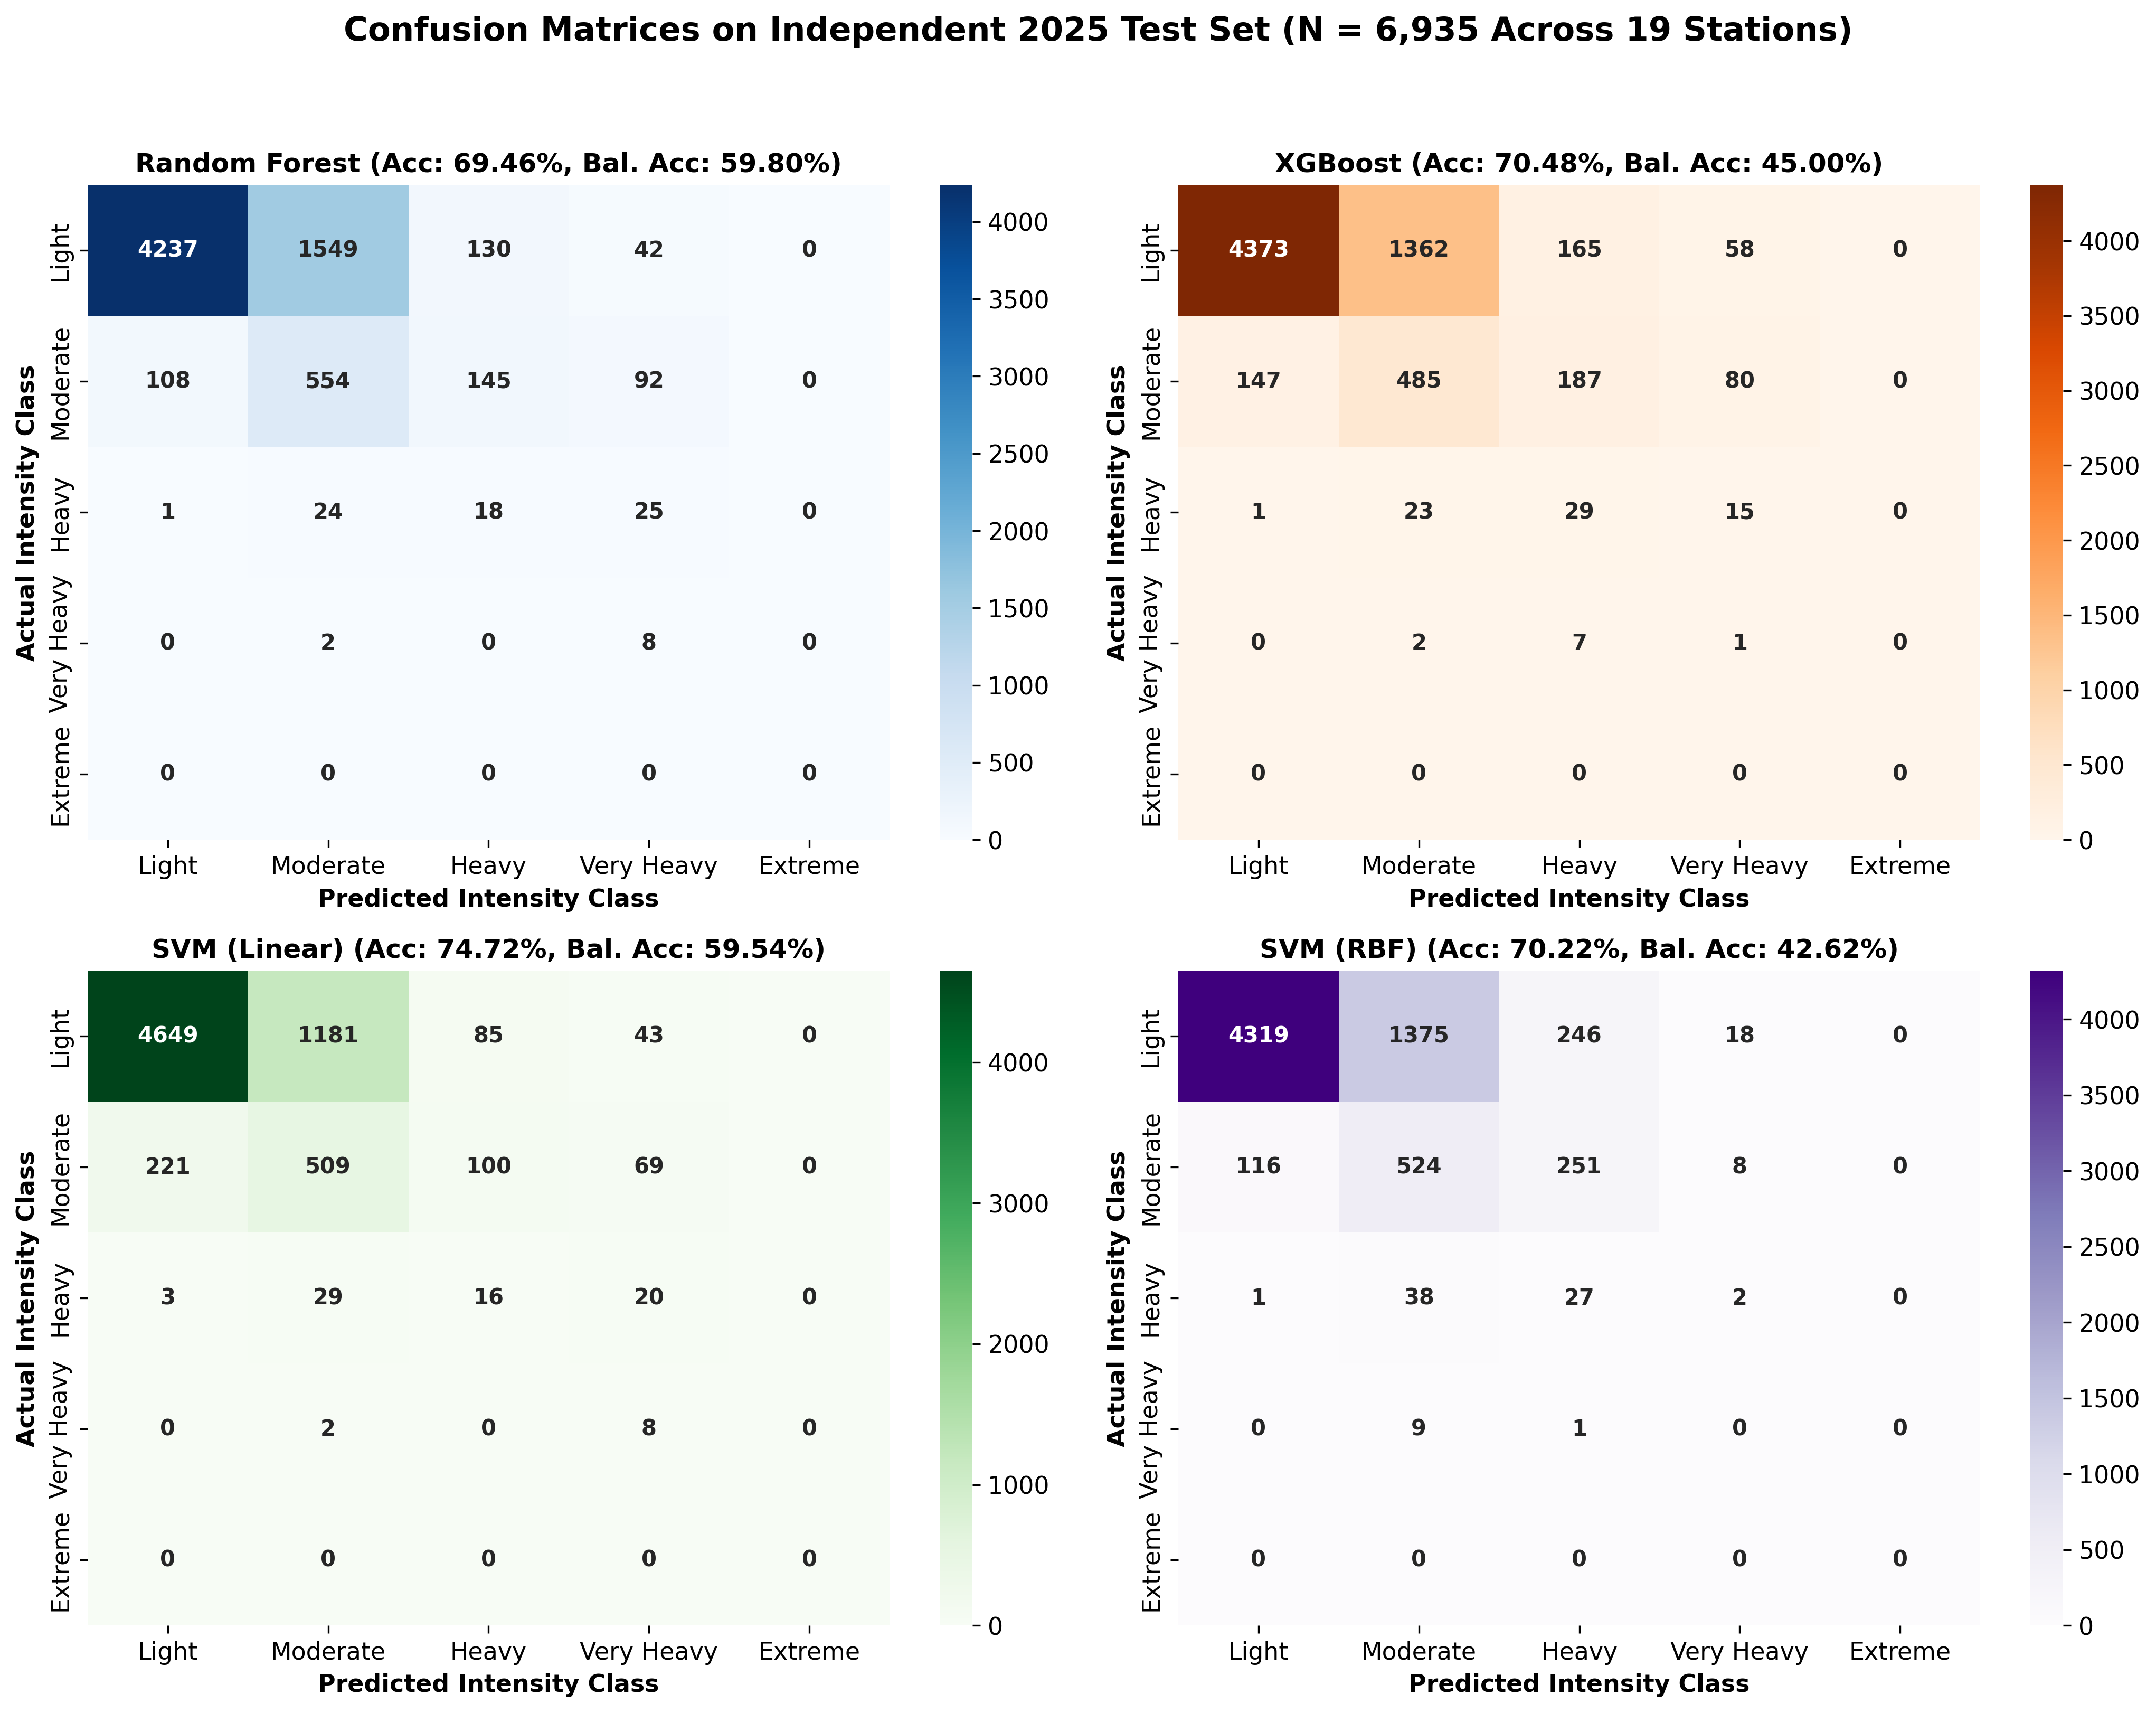

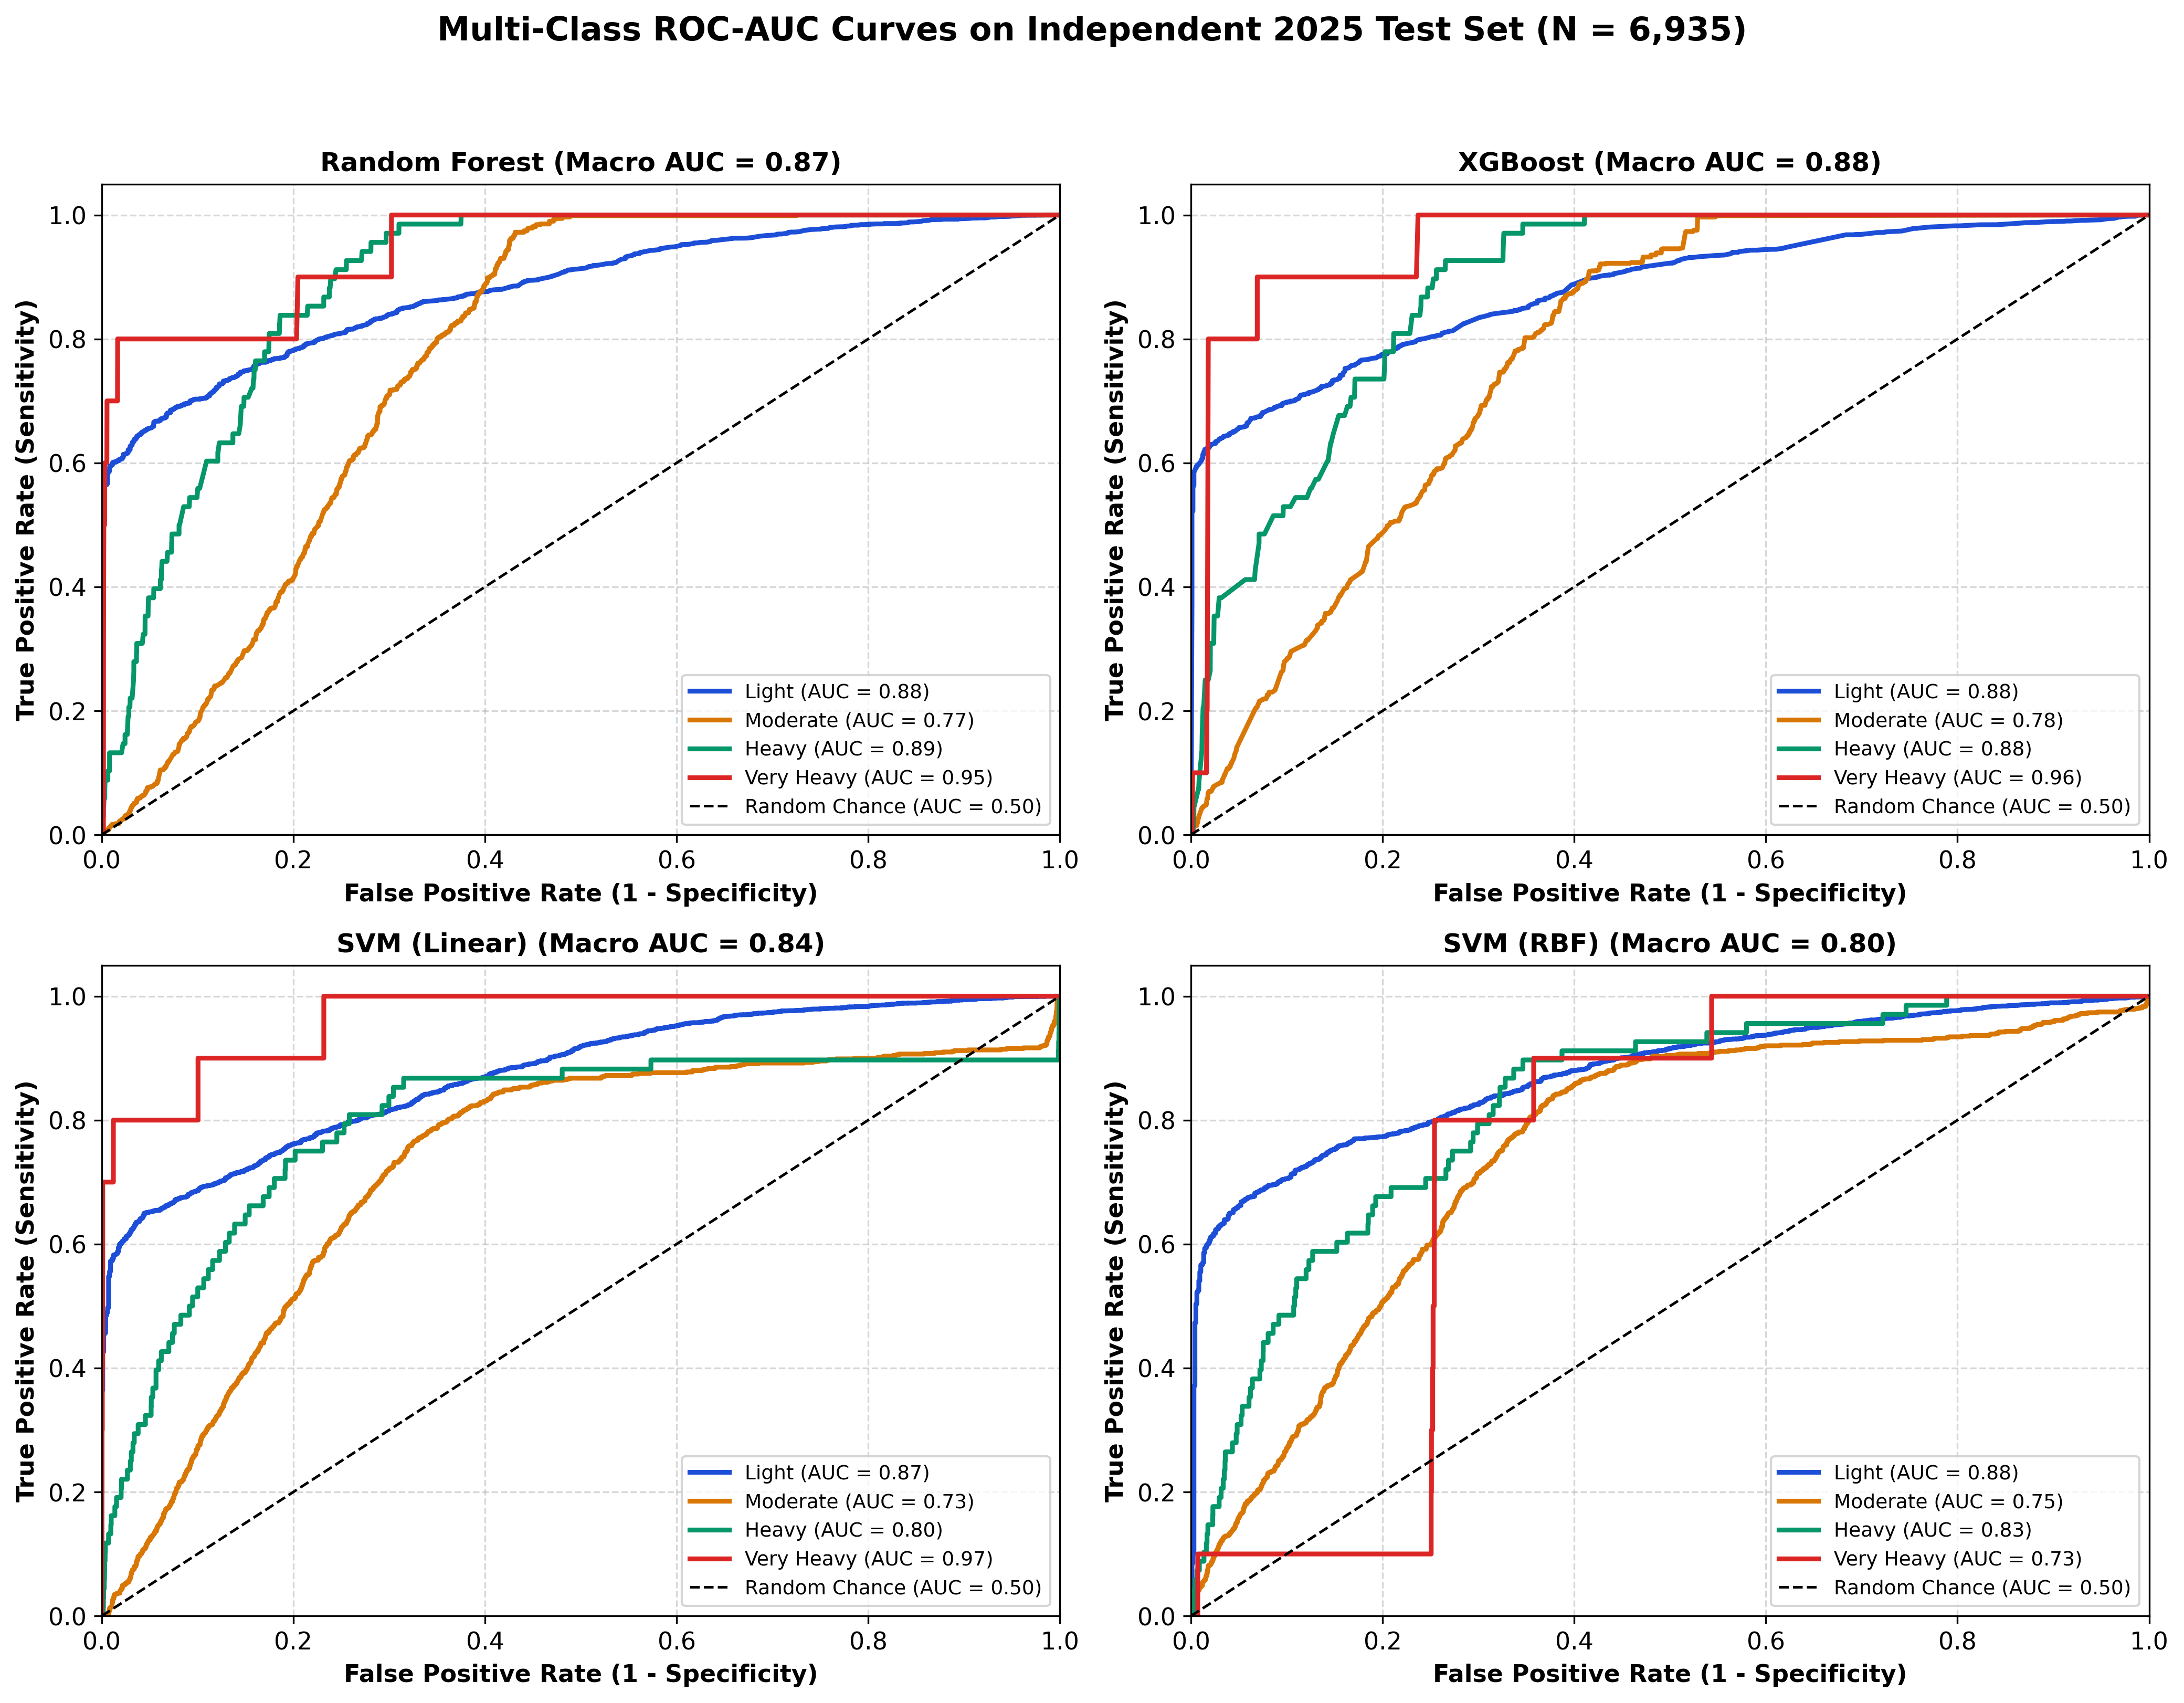

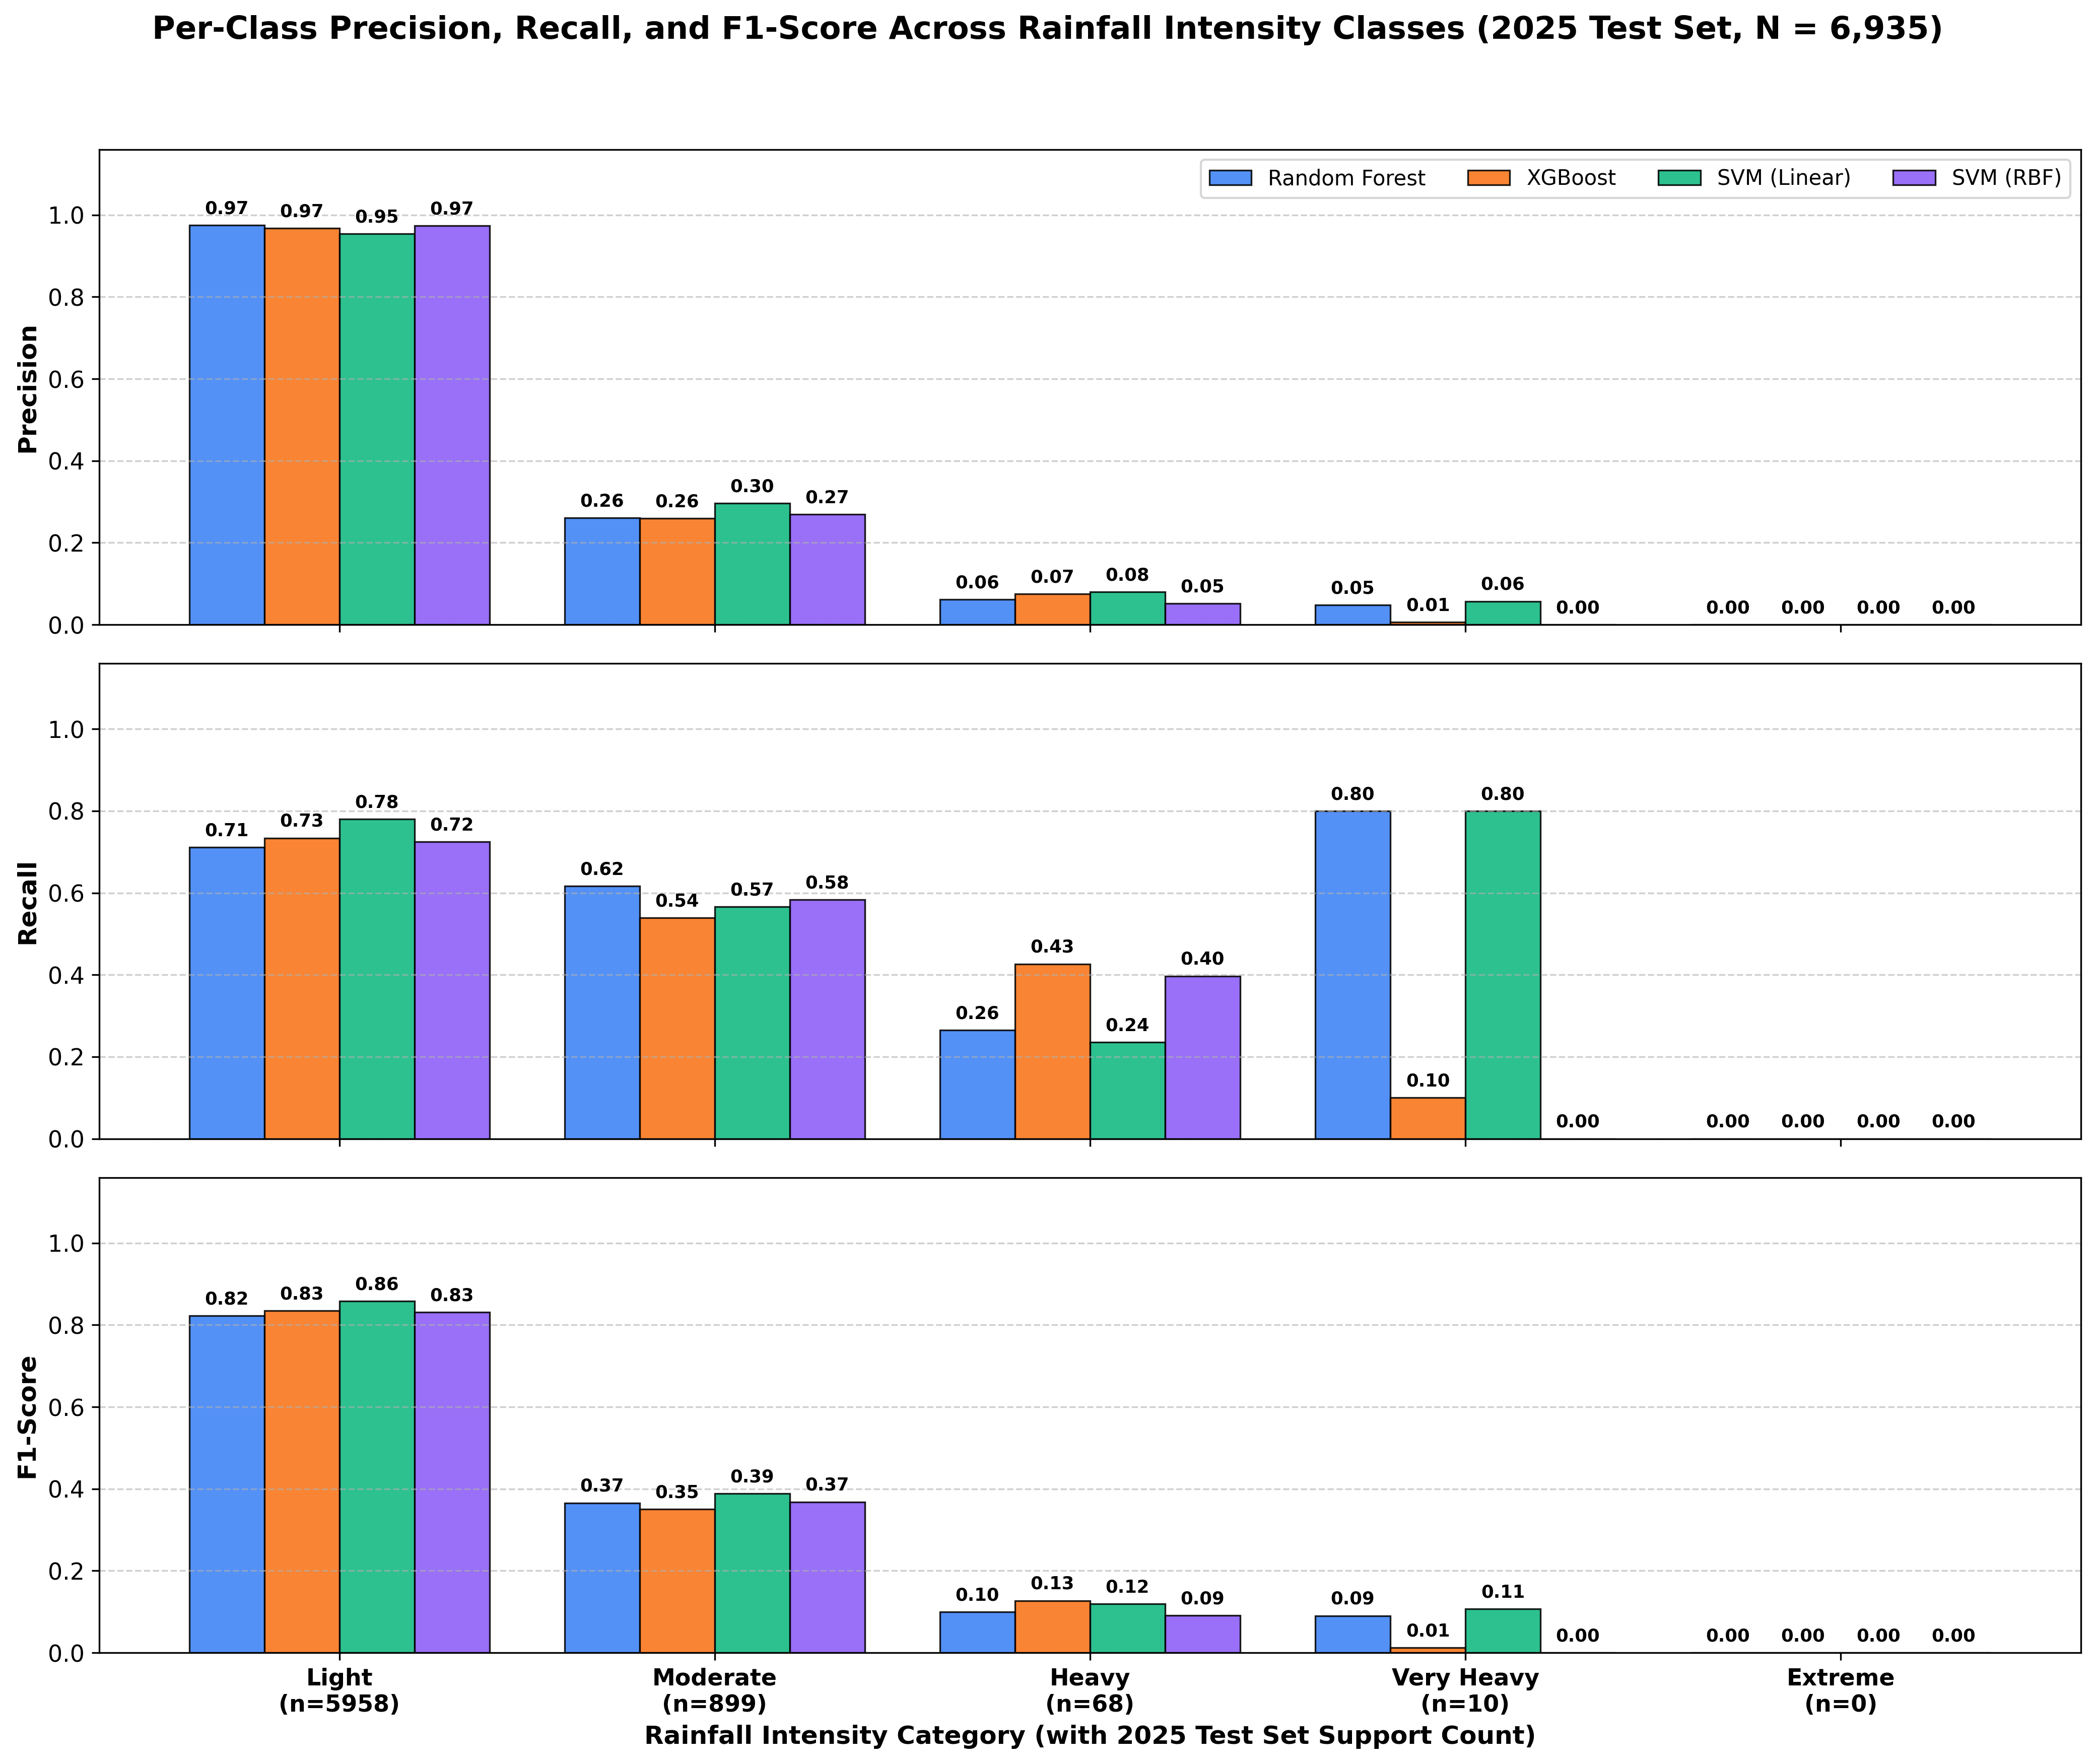

In [ ]:
# Safeguard: ensure metrics are loaded if cell is run independently
if 'balanced_accuracy_score' not in globals():
    from sklearn.metrics import balanced_accuracy_score, accuracy_score, confusion_matrix
if 'OUT_IMG' not in globals():
    OUT_IMG = r'C:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\Assignment\latex_documentation\Overleaf_LaTeX_Upload\output_image'

# 1. Multi-Model Confusion Matrices (2x2 Grid on 2025 Test Set, N = 6,935)
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.suptitle('Confusion Matrices on Independent 2025 Test Set (N = 6,935 Across 19 Stations)', fontsize=15, fontweight='bold', y=0.98)
models_cm = [
    ('Random Forest', rf_model, X_test, 'Blues'),
    ('XGBoost', xgb_model, X_test, 'Oranges'),
    ('SVM (Linear)', svm_linear, X_test_scaled, 'Greens'),
    ('SVM (RBF)', svm_rbf, X_test_scaled, 'Purples')
]

for ax, (name, model, X_eval_m, cmap) in zip(axes.flatten(), models_cm):
    y_pred_m = model.predict(X_eval_m)
    cm = confusion_matrix(y_test, y_pred_m, labels=[0, 1, 2, 3, 4])
    acc_m = accuracy_score(y_test, y_pred_m) * 100
    bal_m = balanced_accuracy_score(y_test, y_pred_m) * 100
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax, xticklabels=class_names, yticklabels=class_names)
    ax.set_title(f'{name} (Acc: {acc_m:.2f}%, Bal. Acc: {bal_m:.2f}%)', fontweight='bold')
    ax.set_ylabel('Actual Intensity Class')
    ax.set_xlabel('Predicted Intensity Class')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(os.path.join(OUT_IMG, 'confusion_matrices.png'))
plt.show()

# 2. Multi-Class ROC-AUC Curves (2x2 Grid on 2025 Test Set)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3, 4])
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.suptitle('Multi-Class ROC-AUC Curves on Independent 2025 Test Set (N = 6,935)', fontsize=15, fontweight='bold', y=0.98)
class_colors = ['#1D4ED8', '#D97706', '#059669', '#DC2626']

for ax, (name, model, X_eval_m, _) in zip(axes.flatten(), models_cm):
    y_score = model.predict_proba(X_eval_m)
    aucs_m = []
    for i in range(4): # Classes 0..3 present in 2025 test set
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc = auc(fpr, tpr)
        aucs_m.append(roc_auc)
        ax.plot(fpr, tpr, color=class_colors[i], lw=2.2, label=f'{class_names[i]} (AUC = {roc_auc:.2f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random Chance (AUC = 0.50)')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate (1 - Specificity)')
    ax.set_ylabel('True Positive Rate (Sensitivity)')
    ax.set_title(f'{name} (Macro AUC = {np.mean(aucs_m):.2f})', fontweight='bold')
    ax.legend(loc='lower right', fontsize=9)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(os.path.join(OUT_IMG, 'roc_curves.png'))
plt.show()

# 3. 3-Panel Per-Class Metrics Bar Chart (Precision, Recall, F1-Score)
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
fig.suptitle('Per-Class Precision, Recall, and F1-Score Across Rainfall Intensity Classes (2025 Test Set, N = 6,935)', fontsize=15, fontweight='bold', y=0.97)
metrics_list = ['Precision', 'Recall', 'F1-Score']
models_info = [
    ('Random Forest', rf_model, X_test, '#3B82F6'),
    ('XGBoost', xgb_model, X_test, '#F97316'),
    ('SVM (Linear)', svm_linear, X_test_scaled, '#10B981'),
    ('SVM (RBF)', svm_rbf, X_test_scaled, '#8B5CF6')
]
x = np.arange(len(class_names))
width = 0.20
all_metrics = {name: precision_recall_fscore_support(y_test, model.predict(X_ev), labels=[0,1,2,3,4], zero_division=0)[:-1] for name, model, X_ev, _ in models_info}

for i, ax in enumerate(axes):
    for j, (name, _, _, color) in enumerate(models_info):
        metric_values = all_metrics[name][i]
        offset = (j - 1.5) * width
        bars = ax.bar(x + offset, metric_values, width, label=name, color=color, alpha=0.88, edgecolor='black', linewidth=0.8)
        for bar in bars:
            yval = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f'{yval:.2f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
    ax.set_ylabel(metrics_list[i], fontsize=12, fontweight='bold')
    ax.set_ylim(0, 1.16)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    if i == 0:
        ax.legend(loc='upper right', ncol=4)
axes[2].set_xticks(x)
axes[2].set_xticklabels(class_names, fontsize=11, fontweight='bold')
axes[2].set_xlabel('Rainfall Intensity Category', fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(os.path.join(OUT_IMG, 'per_class_metrics_barchart.png'))
plt.show()


## 8. Model Interpretability & Explainable AI (SHAP)
Opening the machine learning "black box" using native tree feature importance and **SHAP (SHapley Additive exPlanations)** values to quantify the directional impact of concurrent rainfall, antecedent lags, and topography.

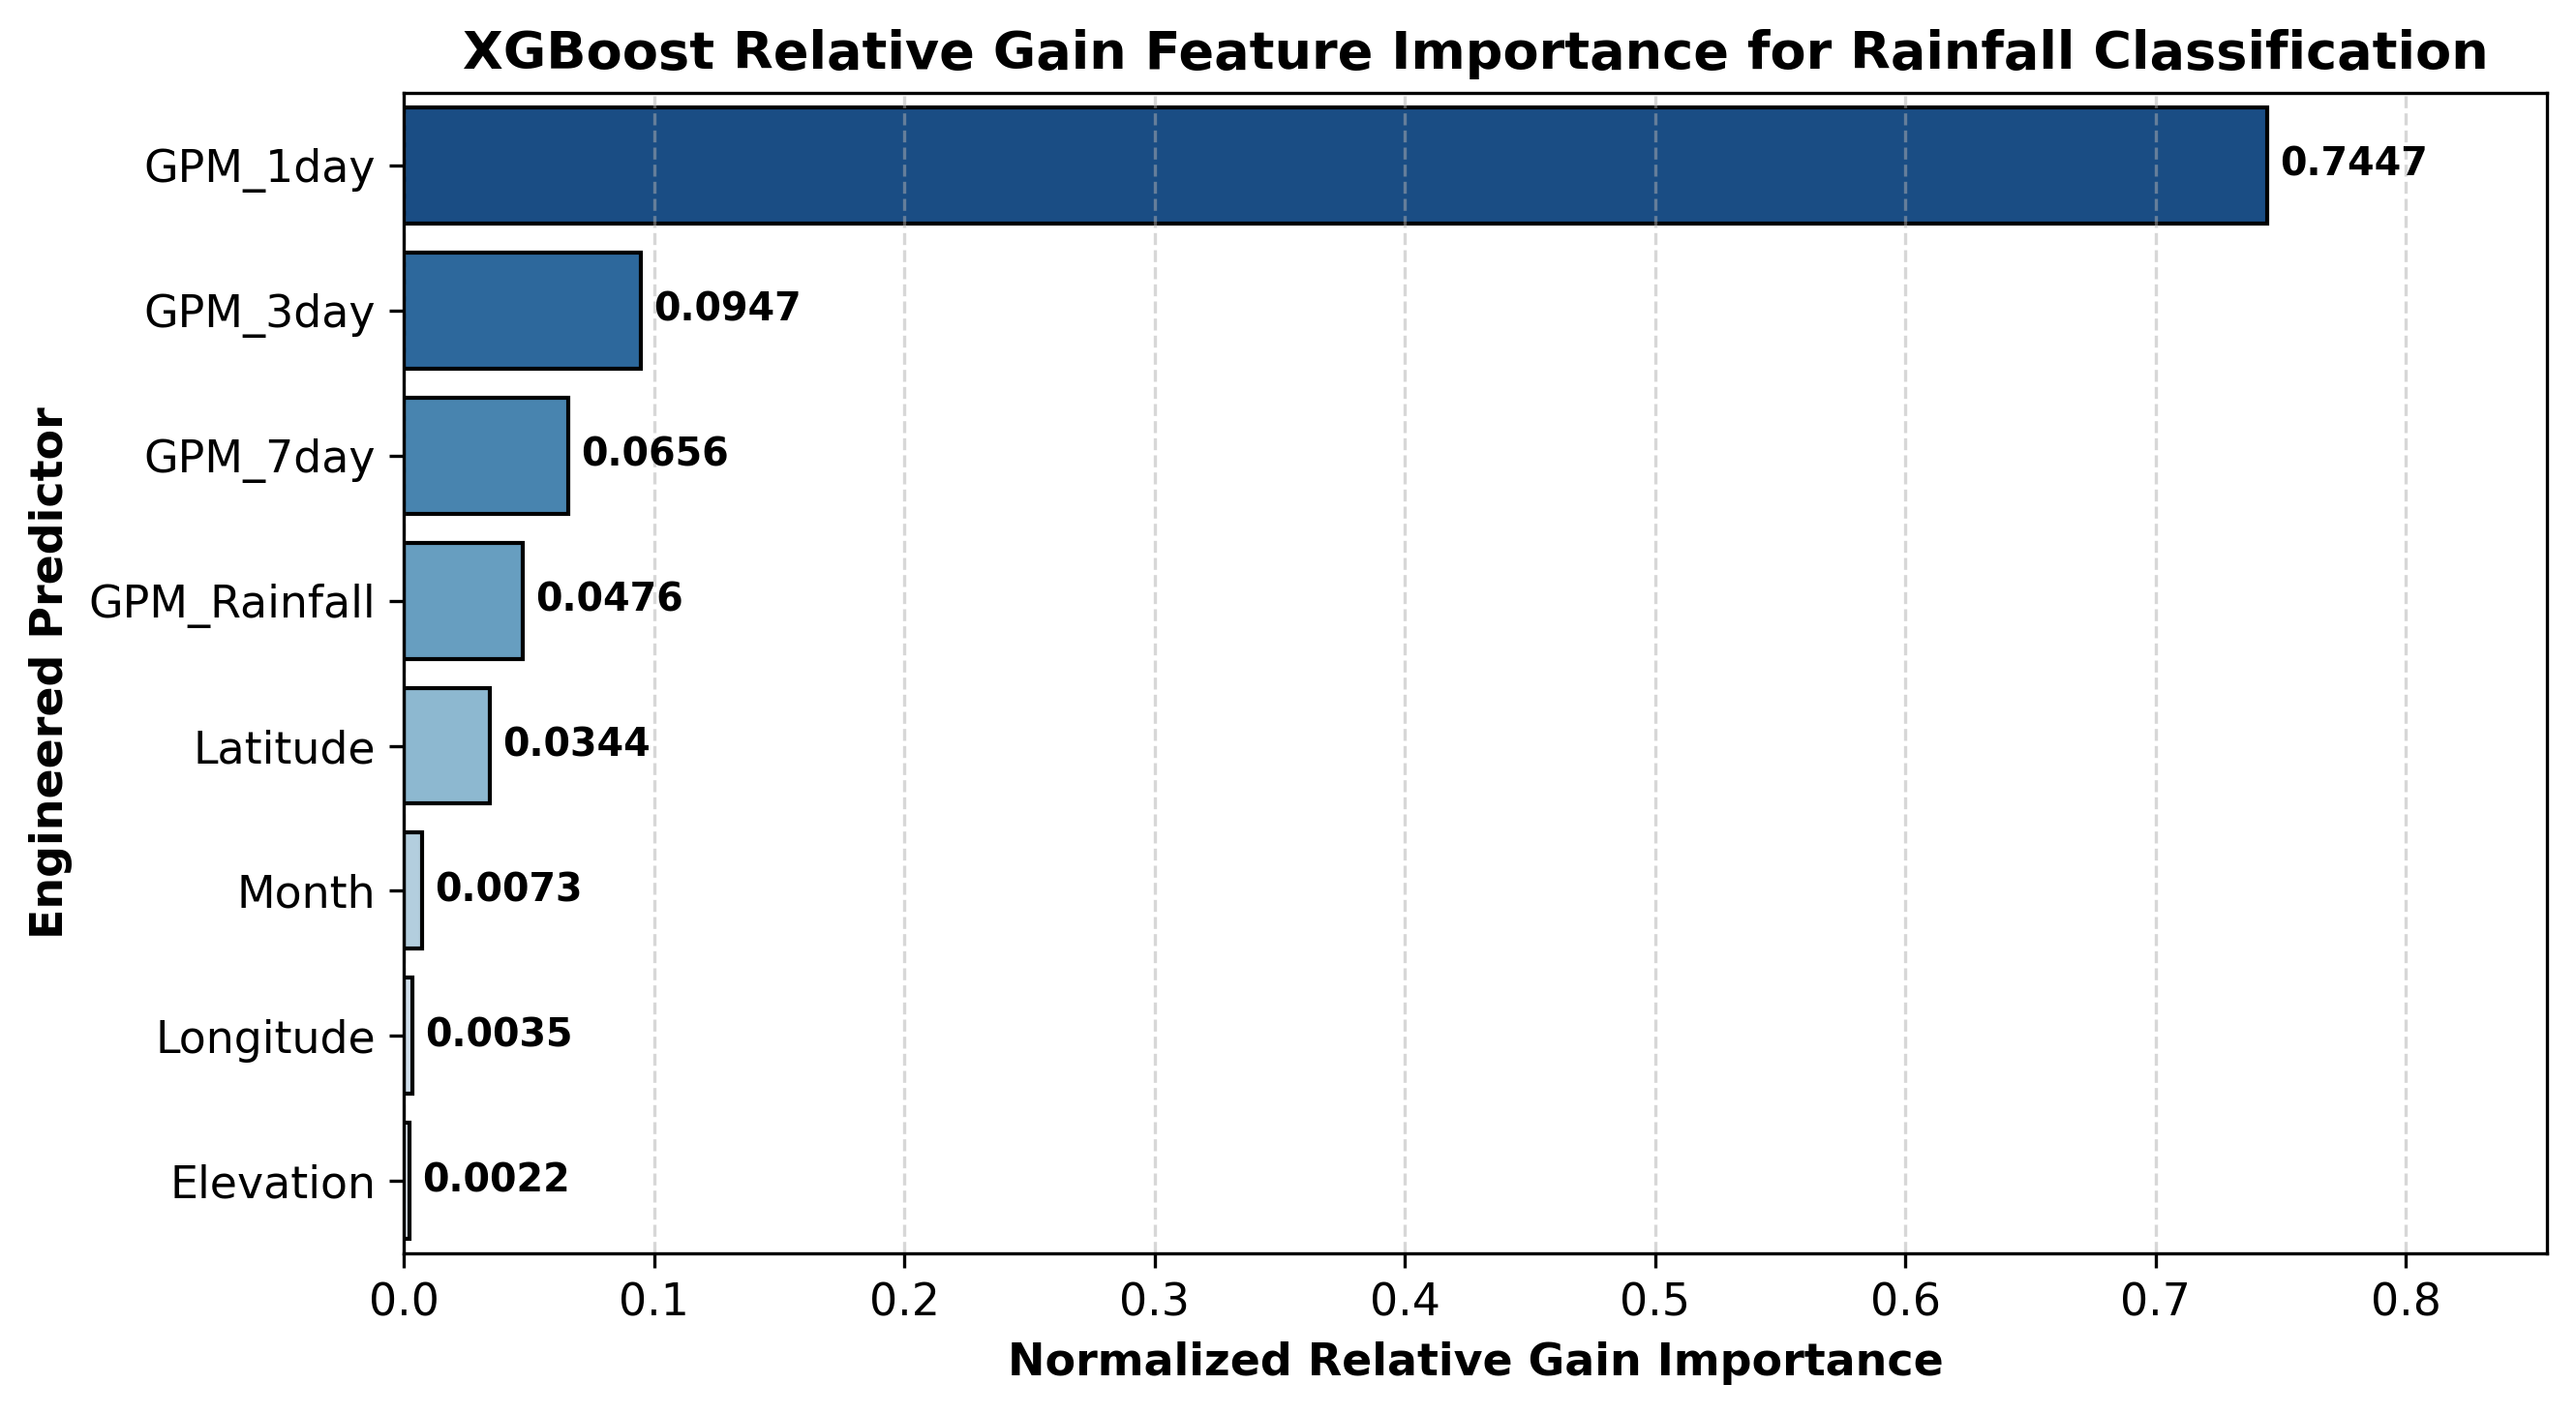

Computing SHAP TreeExplainer values...


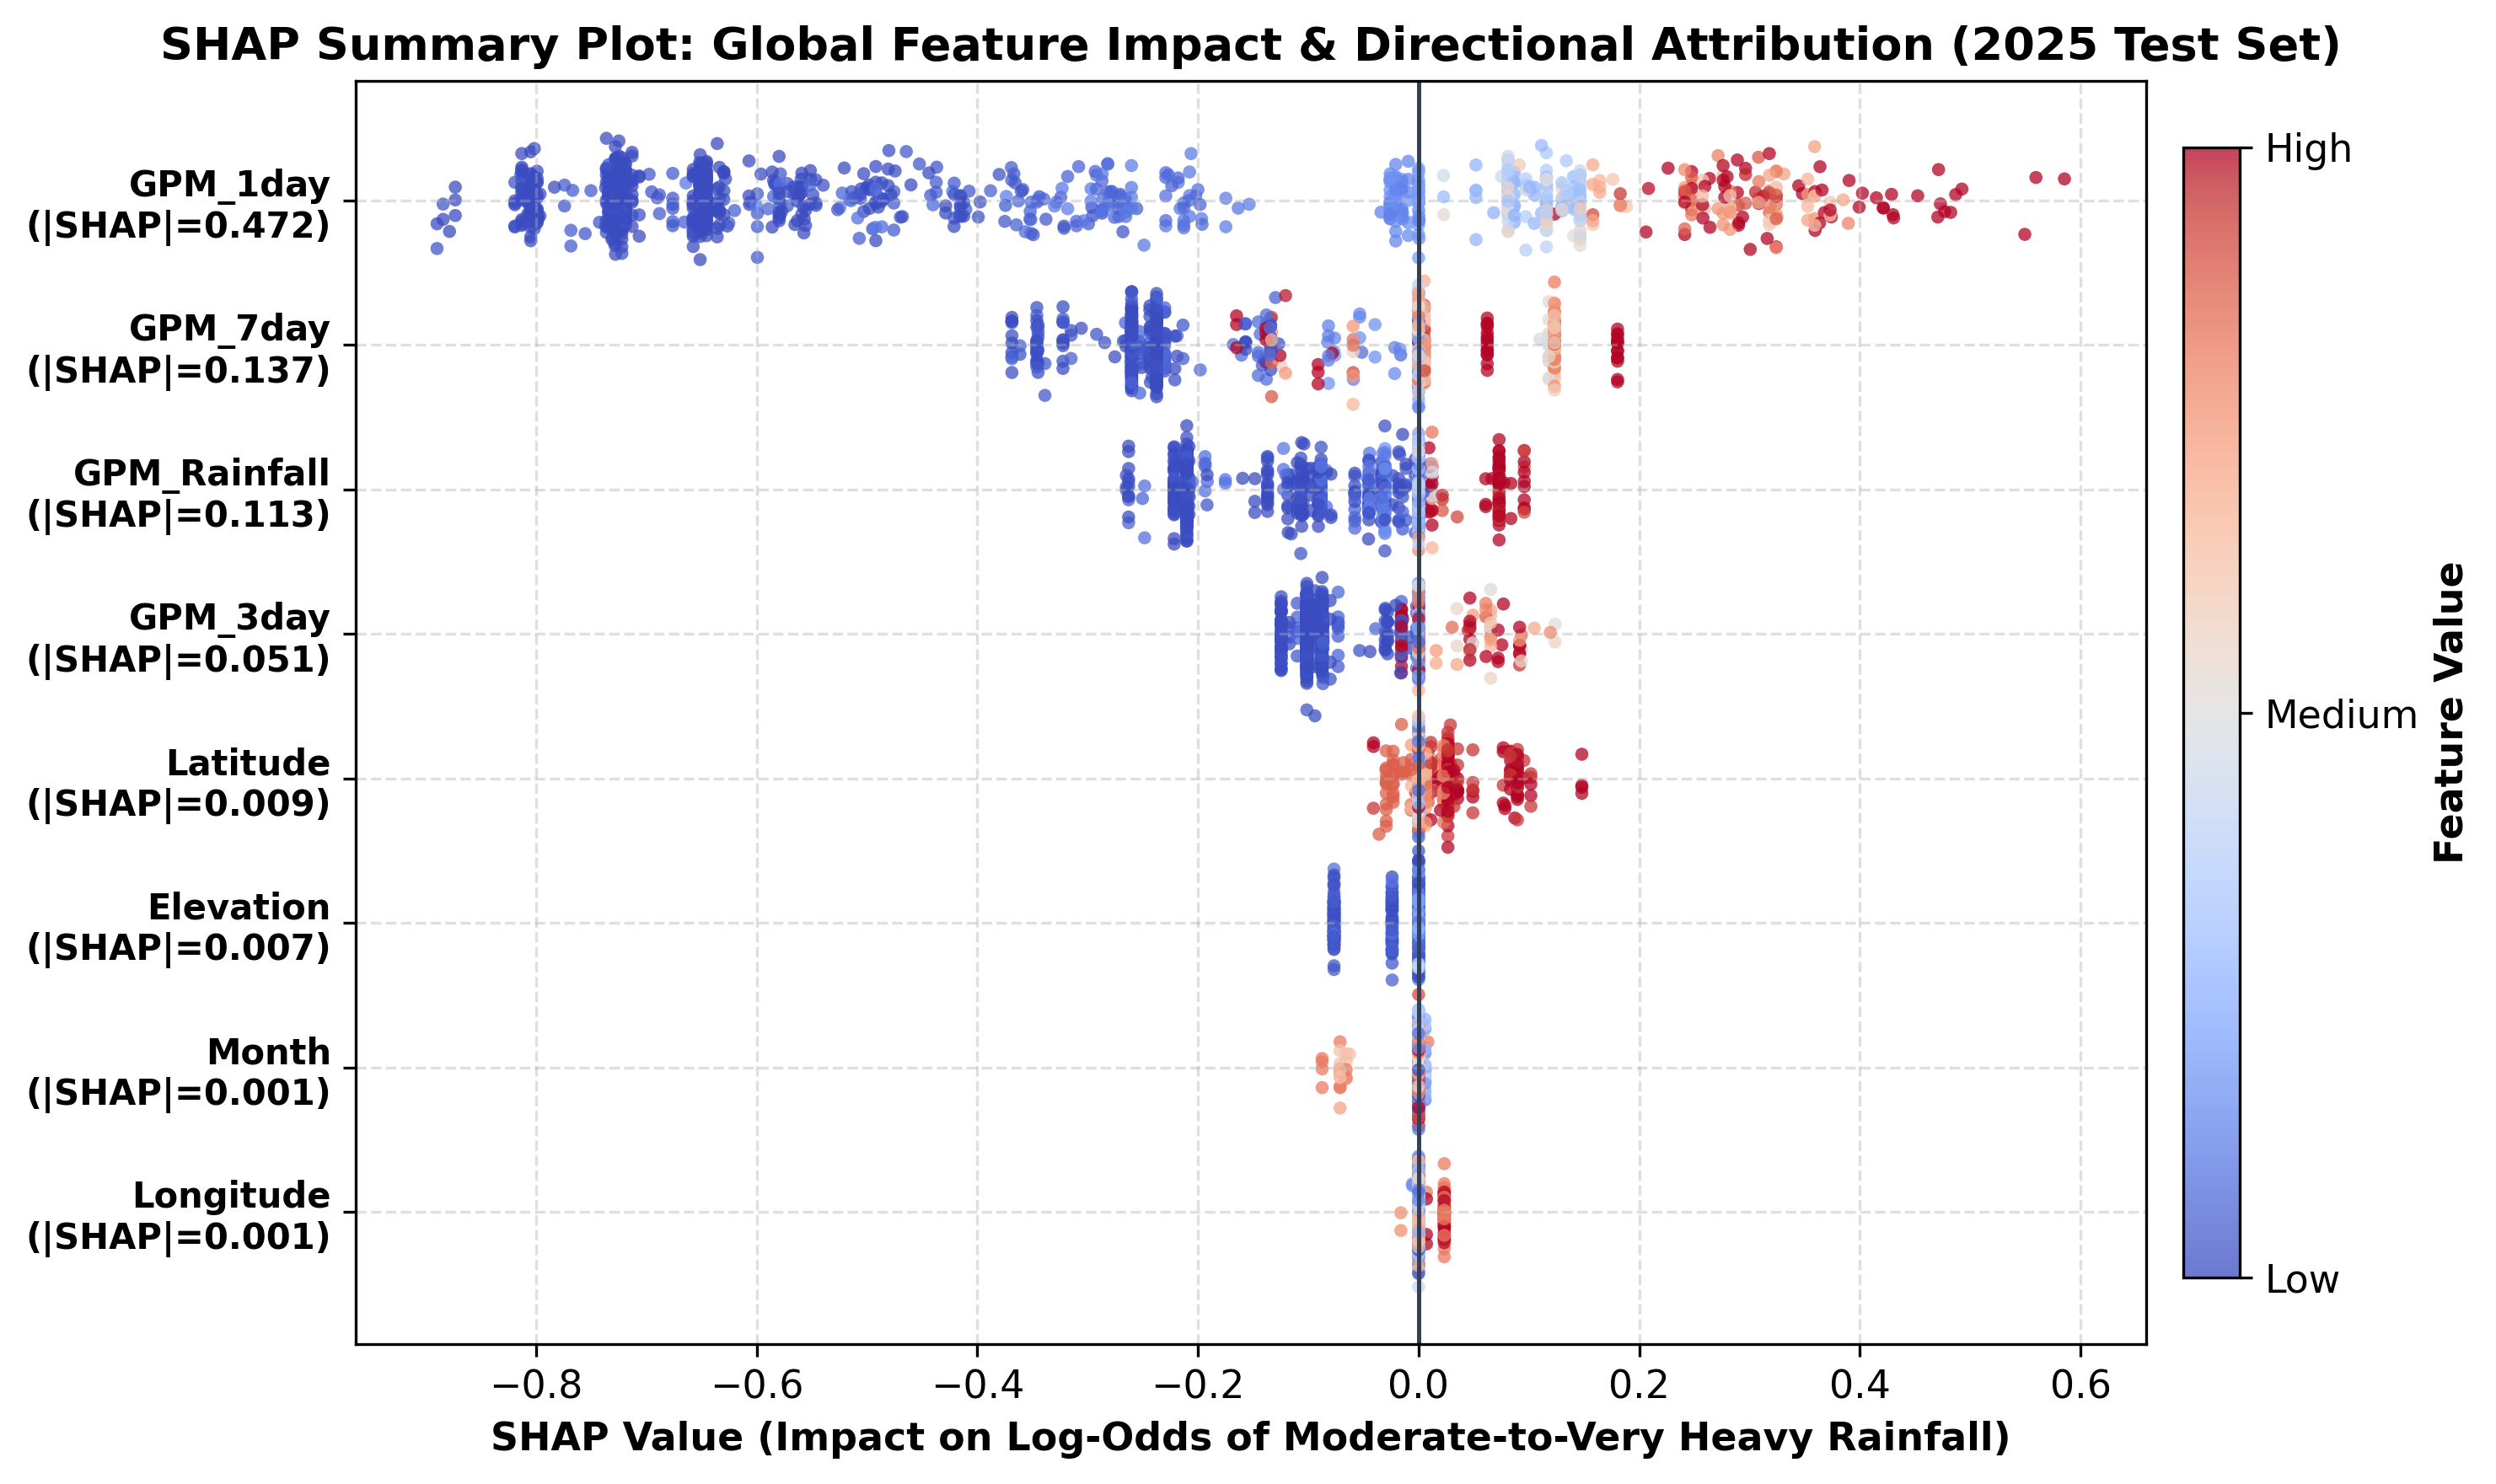

In [ ]:
# 1. Native XGBoost Feature Importance
feat_imp = pd.Series(xgb_model.feature_importances_, index=features).sort_values(ascending=False)
plt.figure(figsize=(9, 5))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='Blues_r')
plt.title('XGBoost Native Feature Importance (Relative Weight)')
plt.xlabel('Importance Score')
plt.savefig(os.path.join(OUT_IMG, 'fig4_feature_importance.png'))
plt.show()

# 2. SHAP Global Summary Plot
print('Computing SHAP TreeExplainer values...')
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title('SHAP Summary: Global Feature Impact on Rainfall Intensity Predictions', y=1.02)
plt.savefig(os.path.join(OUT_IMG, 'shap_summary.png'))
plt.show()

## 9. Satellite Product Validation & Topographic Bias
Replicating **Sharma et al. (2020)** and **Talchabhadel et al. (2021)**:
* Generating a **Taylor Diagram** (SkillMetrics) evaluating correlation, RMSD, and standard deviation.
* Calculating categorical contingency metrics: **Probability of Detection (POD)**, **False Alarm Ratio (FAR)**, and **Critical Success Index (CSI)**.
* Assessing elevation-dependent satellite error across the Himalayan terrain.

In [ ]:
# Safeguard: auto-load df_all and prerequisites if cell is executed independently
if 'OUT_IMG' not in globals():
    OUT_IMG = r'C:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\Assignment\latex_documentation\Overleaf_LaTeX_Upload\output_image'
if 'df_all' not in globals():
    import os, pandas as pd, numpy as np
    for _p in [
        r'C:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\Assignment\results\dhm_gpm_spatiotemporal_features.csv',
        r'C:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\bak\results\dhm_gpm_spatiotemporal_features.csv'
    ]:
        if os.path.exists(_p):
            df_all = pd.read_csv(_p)
            print(f'Auto-loaded df_all from: {_p} ({len(df_all):,} records)')
            break

dhm = df_all['DHM_Rainfall'].values
gpm = df_all['GPM_Rainfall'].values

# 1. Continuous Metrics
corr = np.corrcoef(dhm, gpm)[0, 1]
bias = np.mean(gpm - dhm)
rmse = np.sqrt(mean_squared_error(dhm, gpm))
nse = 1 - (np.sum((dhm - gpm) ** 2) / np.sum((dhm - np.mean(dhm)) ** 2))

print('--- Continuous Validation Metrics (GPM IMERG vs DHM Ground) ---')
print(f'Pearson Correlation (r):     {corr:.4f}')
print(f'Mean Bias:                   {bias:.4f} mm/day')
print(f'Root Mean Square Error:      {rmse:.4f} mm/day')
print(f'Nash-Sutcliffe Efficiency:   {nse:.4f}')

# 2. Taylor Diagram
taylor_stats = sm.taylor_statistics(gpm, dhm, 'data')
sdev = np.array([taylor_stats['sdev'][0], taylor_stats['sdev'][1]])
crmsd = np.array([taylor_stats['crmsd'][0], taylor_stats['crmsd'][1]])
ccoef = np.array([taylor_stats['ccoef'][0], taylor_stats['ccoef'][1]])

plt.figure(figsize=(7, 7))
sm.taylor_diagram(sdev, crmsd, ccoef, markerLabel=['Observation (DHM)', 'GPM IMERG'],
                  markerLegend='on', styleOBS='-', colOBS='r', markerobs='o', titleOBS='Ground Truth')
plt.title('Taylor Diagram: GPM IMERG vs DHM Ground Truth', y=1.05)
plt.savefig(os.path.join(OUT_IMG, 'taylor_diagram.png'))
plt.show()

# 3. Sharma et al. (2020) Categorical Metrics
threshold = 1.0 # Rainy day > 1mm
hits = np.sum((dhm >= threshold) & (gpm >= threshold))
misses = np.sum((dhm >= threshold) & (gpm < threshold))
false_alarms = np.sum((dhm < threshold) & (gpm >= threshold))

pod = hits / (hits + misses) if (hits + misses) > 0 else 0
far = false_alarms / (hits + false_alarms) if (hits + false_alarms) > 0 else 0
csi = hits / (hits + misses + false_alarms) if (hits + misses + false_alarms) > 0 else 0

print('\n--- Categorical Metrics (Sharma et al., 2020) ---')
print(f'Probability of Detection (POD): {pod:.4f}')
print(f'False Alarm Ratio (FAR):        {far:.4f}')
print(f'Critical Success Index (CSI):   {csi:.4f}')

# 4. Topographic Bias: Elevation vs Satellite Error
df_all['GPM_Error'] = df_all['GPM_Rainfall'] - df_all['DHM_Rainfall']
plt.figure(figsize=(9, 5))
sns.regplot(data=df_all, x='Elevation', y='GPM_Error', scatter_kws={'alpha':0.1, 'color':'darkred'}, line_kws={'color':'black'})
plt.title('Topographic Dependency: Elevation vs GPM Error (Talchabhadel, 2021)')
plt.ylabel('GPM Error (Satellite - Ground mm/day)')
plt.xlabel('Station Elevation (meters)')
plt.axhline(0, color='blue', linestyle='--')
plt.savefig(os.path.join(OUT_IMG, 'elevation_bias.png'))
plt.show()

NameError: name 'df_all' is not defined

## 10. Long-Term Climate Trend Analysis (Mann–Kendall & Sen's Slope)
Evaluating statistical temporal shifts across **2016–2025** using non-parametric Mann–Kendall trend tests and Sen's slope estimator across four hydrometeorological indicators:
1. **Annual Mean Rainfall**
2. **Maximum Daily Rainfall**
3. **Frequency of Rainy Days ($>1$ mm)**
4. **Frequency of Extreme Events ($\ge 100$ mm)**

--- Mann-Kendall Trend Analysis Results ---
Annual Mean Rainfall: Trend=increasing, p-value=0.0491, Tau=0.5111, Slope=0.2012
Max Daily Rainfall: Trend=no trend, p-value=0.1780, Tau=0.3556, Slope=2.4800
Rainy Days (>1mm): Trend=no trend, p-value=0.1524, Tau=0.3778, Slope=40.1667
Extreme Events (>100mm): Trend=no trend, p-value=0.1491, Tau=0.3778, Slope=0.8889


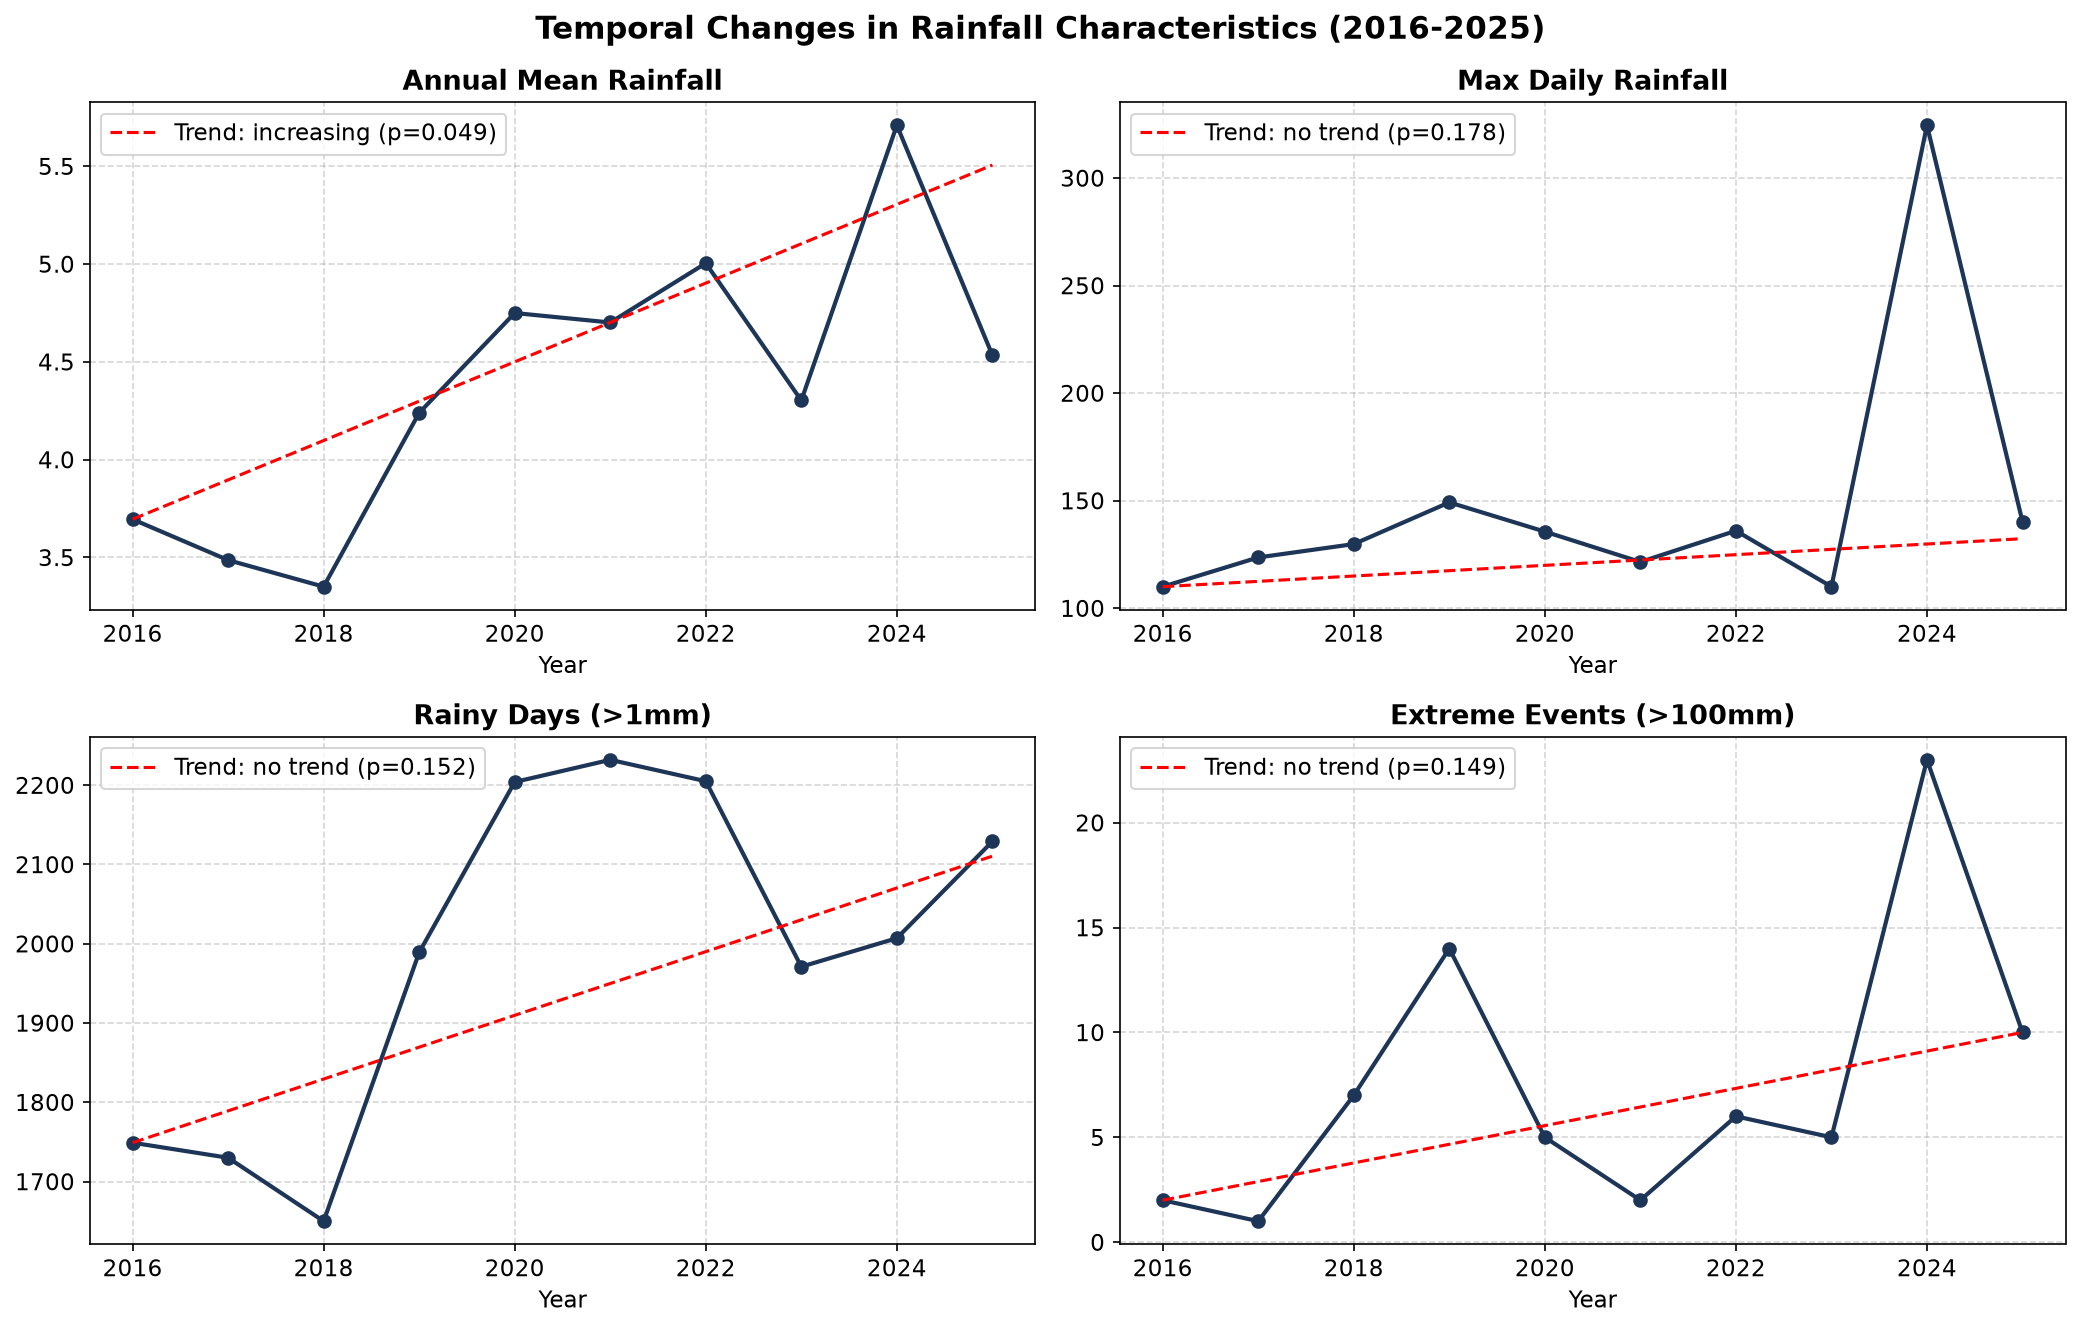

In [ ]:
# Safeguard: auto-load df_all and prerequisites if cell is executed independently
if 'OUT_IMG' not in globals():
    OUT_IMG = r'C:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\Assignment\latex_documentation\Overleaf_LaTeX_Upload\output_image'
if 'df_all' not in globals():
    import os, pandas as pd, numpy as np
    for _p in [
        r'C:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\Assignment\results\dhm_gpm_spatiotemporal_features.csv',
        r'C:\Users\ADMIN\Downloads\SA_260102_ML_Assignment_Clean\bak\results\dhm_gpm_spatiotemporal_features.csv'
    ]:
        if os.path.exists(_p):
            df_all = pd.read_csv(_p)
            print(f'Auto-loaded df_all from: {_p} ({len(df_all):,} records)')
            break

trend_metrics = {
    'Annual Mean Rainfall': df_all.groupby('Year')['DHM_Rainfall'].mean(),
    'Max Daily Rainfall': df_all.groupby('Year')['DHM_Rainfall'].max(),
    'Rainy Days (>1mm)': df_all[df_all['DHM_Rainfall'] > 1].groupby('Year')['DHM_Rainfall'].count(),
    'Extreme Events (>100mm)': df_all[df_all['DHM_Rainfall'] >= 100].groupby('Year')['DHM_Rainfall'].count()
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Temporal Changes in Rainfall Characteristics (2016-2025)', fontsize=15, fontweight='bold')
axes = axes.flatten()

print('--- Mann-Kendall Trend Analysis Results ---')
for idx, (title, series) in enumerate(trend_metrics.items()):
    res = mk.original_test(series.values)
    print(f'{title}: Trend={res.trend}, p-value={res.p:.4f}, Tau={res.Tau:.4f}, Slope={res.slope:.4f}')
    
    ax = axes[idx]
    ax.plot(series.index, series.values, marker='o', linestyle='-', color='#1D3557', lw=2)
    
    # Calculate and plot Sen\'s slope trend line
    trend_line = [series.values[0] + res.slope * i for i in range(len(series))]
    ax.plot(series.index, trend_line, color='red', linestyle='--', label=f'Trend: {res.trend} (p={res.p:.3f})')
    
    ax.set_title(f'{title}', fontweight='bold')
    ax.set_xlabel('Year')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='best')

plt.tight_layout()
plt.savefig(os.path.join(OUT_IMG, 'comprehensive_trend_analysis.png'))
plt.show()